# TP3 - CNNs en imágenes satelitales

> Utilizaremos el dataset EuroSAT para entrenar un modelo de redes neuronales convolucionales. La idea principal es identificar distintos tipos de uso del suelo a través de imágenes.

> Para crear el modelo de CNNs utilizaremos la biblioteca *PyTorch*. Esta biblioteca es de aprendizaje automático y deep learning. Podemos crear tensores, usar diferenciación automática y construir redes neuronales.

**Descripción del dataset.** EuroSAT contiene imágenes satelitales del satélite Sentinel-2 (versión RGB).
Cada imagen tiene 64 × 64 píxeles y cada píxel cubre 10 m × 10 m de terreno, por lo que una imagen
representa un área de 640 m × 640 m. Hay 10 clases de uso del suelo:

| Clase | Descripción |
|---|---|
| AnnualCrop | Cultivos que se siembran y cosechan cada año (parcelas rectangulares) |
| PermanentCrop | Cultivos permanentes: viñedos, frutales, olivares |
| Pasture | Pasturas para ganado |
| HerbaceousVegetation | Vegetación herbácea natural, sin uso agrícola |
| Forest | Bosques |
| Highway | Rutas y autopistas |
| Industrial | Zonas industriales y comerciales |
| Residential | Zonas residenciales |
| River | Ríos |
| SeaLake | Mar y lagos |


In [1]:
# Bibliotecas

import pandas as pd
import torch
import matplotlib.pyplot as plt 
from torchvision import transforms
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn # Para crear la CNN.
import time # Para no pasarnos de tiempo en el entrenamiento.
import copy # Para guardar una copia de los pesos de la mejor época.

# Seed

torch.manual_seed(42)

# Directorio de datos

DATA_DIR = "EuroSAT" # Directorio donde se encuentran los datos.

#### 1- Realizamos un análisis exploratorio de los datos (EDA).

> Lo realizamos para mirar y entender los datos antes de modelar. Sin entrenar, podemos hacernos preguntas sobre el dataset.

> Podemos detectar problemas antes de entrenar, tomar decisiones de preprocesamiento y anticipar resultados.

In [2]:
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
validation_df = pd.read_csv(f"{DATA_DIR}/validation.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")

In [3]:
train_df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,16257,AnnualCrop/AnnualCrop_142.jpg,0,AnnualCrop
1,3297,HerbaceousVegetation/HerbaceousVegetation_2835...,2,HerbaceousVegetation
2,17881,PermanentCrop/PermanentCrop_1073.jpg,6,PermanentCrop
3,2223,Industrial/Industrial_453.jpg,4,Industrial
4,4887,HerbaceousVegetation/HerbaceousVegetation_1810...,2,HerbaceousVegetation


In [4]:
validation_df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,258,Pasture/Pasture_1481.jpg,5,Pasture
1,2134,Forest/Forest_2638.jpg,1,Forest
2,3518,Highway/Highway_875.jpg,3,Highway
3,3048,River/River_434.jpg,8,River
4,3996,SeaLake/SeaLake_2930.jpg,9,SeaLake


In [5]:
test_df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,2438,AnnualCrop/AnnualCrop_1275.jpg,0,AnnualCrop
1,1018,Residential/Residential_504.jpg,7,Residential
2,3,Pasture/Pasture_787.jpg,5,Pasture
3,1011,Residential/Residential_1575.jpg,7,Residential
4,47,Pasture/Pasture_473.jpg,5,Pasture


In [3]:
# Limpieza de datos:
# Descartamos la primera columna que no aporta valor alguno. Solamente es el indice que tenia en la fila en el dataset original.

test_df = test_df.drop(columns=["Unnamed: 0"])

validation_df = validation_df.drop(columns=["Unnamed: 0"])

train_df = train_df.drop(columns=["Unnamed: 0"])

In [7]:
# Tamaño de los datasets:

test_df.shape[0]

2700

In [8]:
validation_df.shape[0]

5400

In [9]:
train_df.shape[0]

18900

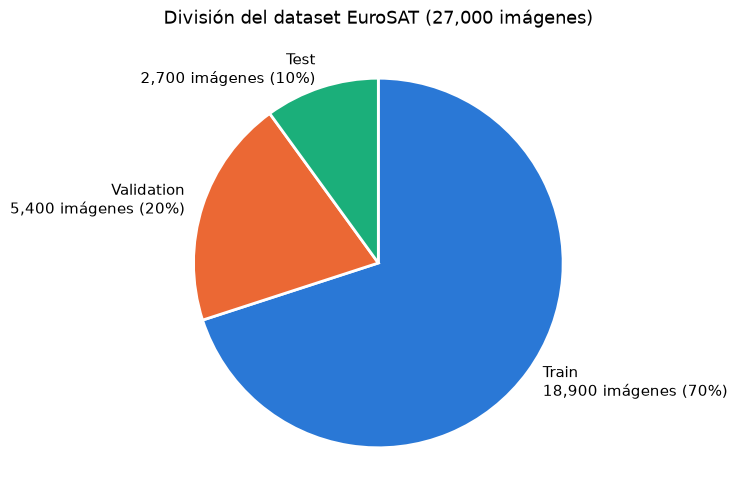

In [10]:
import matplotlib.pyplot as plt

# 1) Datos: nombre y cantidad de imágenes de cada split
nombres = ["Train", "Validation", "Test"]
tamaños = [len(train_df), len(validation_df), len(test_df)]  # len() = cantidad de filas
total = sum(tamaños)

# 2) Etiquetas con nombre, cantidad y porcentaje
etiquetas = [
    f"{nombre}\n{tamaño:,} imágenes ({tamaño / total:.0%})"
    for nombre, tamaño in zip(nombres, tamaños)
]

# 3) Gráfico de torta
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    tamaños,
    labels=etiquetas,
    colors=["#2a78d6", "#eb6834", "#1baf7a"],     # un color distinto por split
    startangle=90,                                # arranca desde arriba
    counterclock=False,                           # gira en sentido horario
    wedgeprops={"edgecolor": "white", "linewidth": 2},  # separa las porciones
    textprops={"fontsize": 11},
)
ax.set_title(f"División del dataset EuroSAT ({total:,} imágenes)", fontsize=13)
plt.show()


> Como vemos, la división de datasets está en formato estándar de simple holdout set + validation, y tenemos imágenes de sobra como para entrenar, validar y testear el modelo.

> **¿Las clases están balanceadas?**


In [11]:
# Cantidad de imágenes por clase en cada split
conteos = pd.DataFrame({
    "Train": train_df["ClassName"].value_counts(),
    "Validation": validation_df["ClassName"].value_counts(),
    "Test": test_df["ClassName"].value_counts(),
})

# Proporción de cada clase dentro de su split (cada columna suma 1)
proporciones = pd.DataFrame({
    "Train": train_df["ClassName"].value_counts(normalize=True),
    "Validation": validation_df["ClassName"].value_counts(normalize=True),
    "Test": test_df["ClassName"].value_counts(normalize=True),
})

# Ordenamos de mayor a menor según train
orden = conteos["Train"].sort_values(ascending=False).index
conteos = conteos.loc[orden]
proporciones = proporciones.loc[orden]

print("Cantidad de imágenes por clase:")
print(conteos)
print("\nProporción de cada clase por split (%):")
print((proporciones * 100).round(1))


Cantidad de imágenes por clase:
                      Train  Validation  Test
ClassName                                    
AnnualCrop             2100         600   300
Forest                 2100         600   300
HerbaceousVegetation   2100         600   300
Residential            2100         600   300
SeaLake                2100         600   300
Highway                1750         500   250
PermanentCrop          1750         500   250
Industrial             1750         500   250
River                  1750         500   250
Pasture                1400         400   200

Proporción de cada clase por split (%):
                      Train  Validation  Test
ClassName                                    
AnnualCrop             11.1        11.1  11.1
Forest                 11.1        11.1  11.1
HerbaceousVegetation   11.1        11.1  11.1
Residential            11.1        11.1  11.1
SeaLake                11.1        11.1  11.1
Highway                 9.3         9.3   9.3
Permane

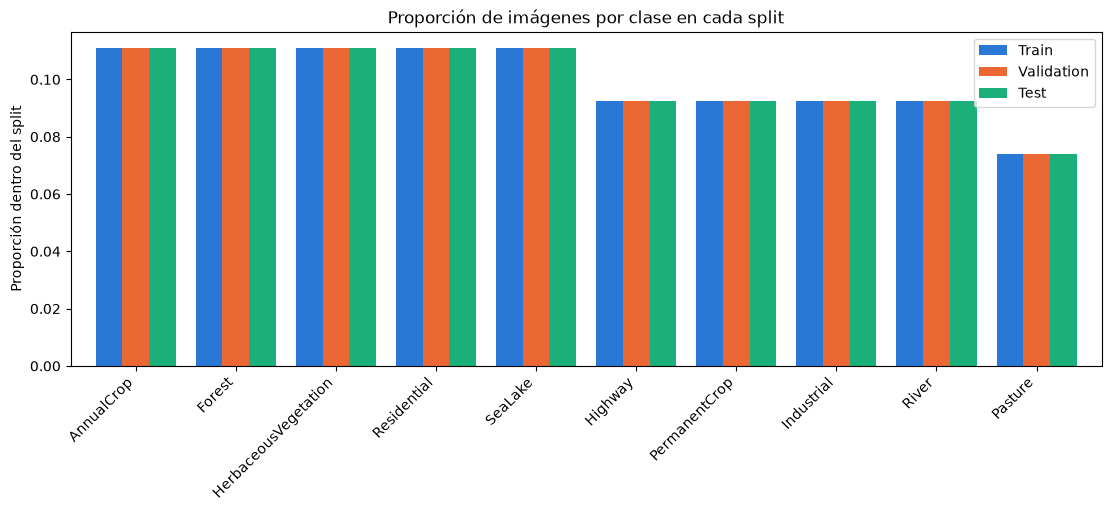

In [12]:
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
proporciones.plot.bar(ax=ax, color=["#2a78d6", "#eb6834", "#1baf7a"], width=0.8)
ax.set_title("Proporción de imágenes por clase en cada split")
ax.set_xlabel("")
ax.set_ylabel("Proporción dentro del split")
plt.xticks(rotation=45, ha="right")
plt.show()


> Como vemos en las tablas y el gráfico generado, hay un desbalance leve por ClassName. En train, las clases más grandes tienen 2.100 imágenes (11,1%) y la más chica, Pasture, tiene 1.400 (7,4%), un 33% menos.

> También vemos que cada split tiene la misma proporción de clases, así que la división es estratificada.

> El data augmentation que vamos a usar no corrige este desbalance, porque se aplica a todas las clases por igual. Lo usamos para que el modelo generalice mejor.

> Como el desbalance es leve, accuracy es una métrica que podemos utilizar, pero la vamos a complementar con métricas por clase para controlar Pasture.

> **¿Hay imágenes duplicadas?**


In [13]:
# Juntamos los tres splits para chequear duplicados entre ellos
todos_df = pd.concat([train_df, validation_df, test_df])

# ¿Alguna imagen aparece más de una vez (dentro de un split o en dos splits distintos)?
print(f"Filas totales: {len(todos_df)}")
print(f"Archivos repetidos: {todos_df['Filename'].duplicated().sum()}")

# ¿La clase de cada fila coincide con la carpeta donde está la imagen?
carpeta = todos_df["Filename"].str.split("/").str[0]
print(f"Filas donde la carpeta no coincide con ClassName: {(carpeta != todos_df['ClassName']).sum()}")

# ¿Cada clase tiene un único Label numérico?
print(todos_df.groupby("ClassName")["Label"].unique())


Filas totales: 27000
Archivos repetidos: 0
Filas donde la carpeta no coincide con ClassName: 0
ClassName
AnnualCrop              [0]
Forest                  [1]
HerbaceousVegetation    [2]
Highway                 [3]
Industrial              [4]
Pasture                 [5]
PermanentCrop           [6]
Residential             [7]
River                   [8]
SeaLake                 [9]
Name: Label, dtype: object


In [ ]:
# ¿Los Label coinciden con label_map.json?
label_map = pd.read_json(f"{DATA_DIR}/label_map.json", typ="series")
print(f"Filas donde Label no coincide con label_map.json: {(todos_df['ClassName'].map(label_map) != todos_df['Label']).sum()}")

# ¿Hay imágenes con los mismos píxeles, dentro de un split o entre splits?
todas_imagenes = torch.stack([torch.from_numpy(plt.imread(f"{DATA_DIR}/{archivo}")) for archivo in todos_df["Filename"]])
imagenes_distintas = len(torch.unique(todas_imagenes.view(len(todas_imagenes), -1), dim=0))
print(f"Imágenes con contenido distinto: {imagenes_distintas} de {len(todas_imagenes)}")

Filas donde Label no coincide con label_map.json: 0
Imágenes con contenido distinto: 27000 de 27000


> En el resultado vemos que no hay imágenes repetidas entre los datasets train, validation y test: ningún archivo se repite y las 27.000 imágenes tienen contenido distinto. Esto descarta copias exactas, pero no imágenes muy parecidas.

> Si hubiera imágenes iguales en train y en test, estaríamos ante un caso de data leakage.

> **¿A qué tipo de imágenes nos enfrentamos? ¿Cuáles se parecen?**

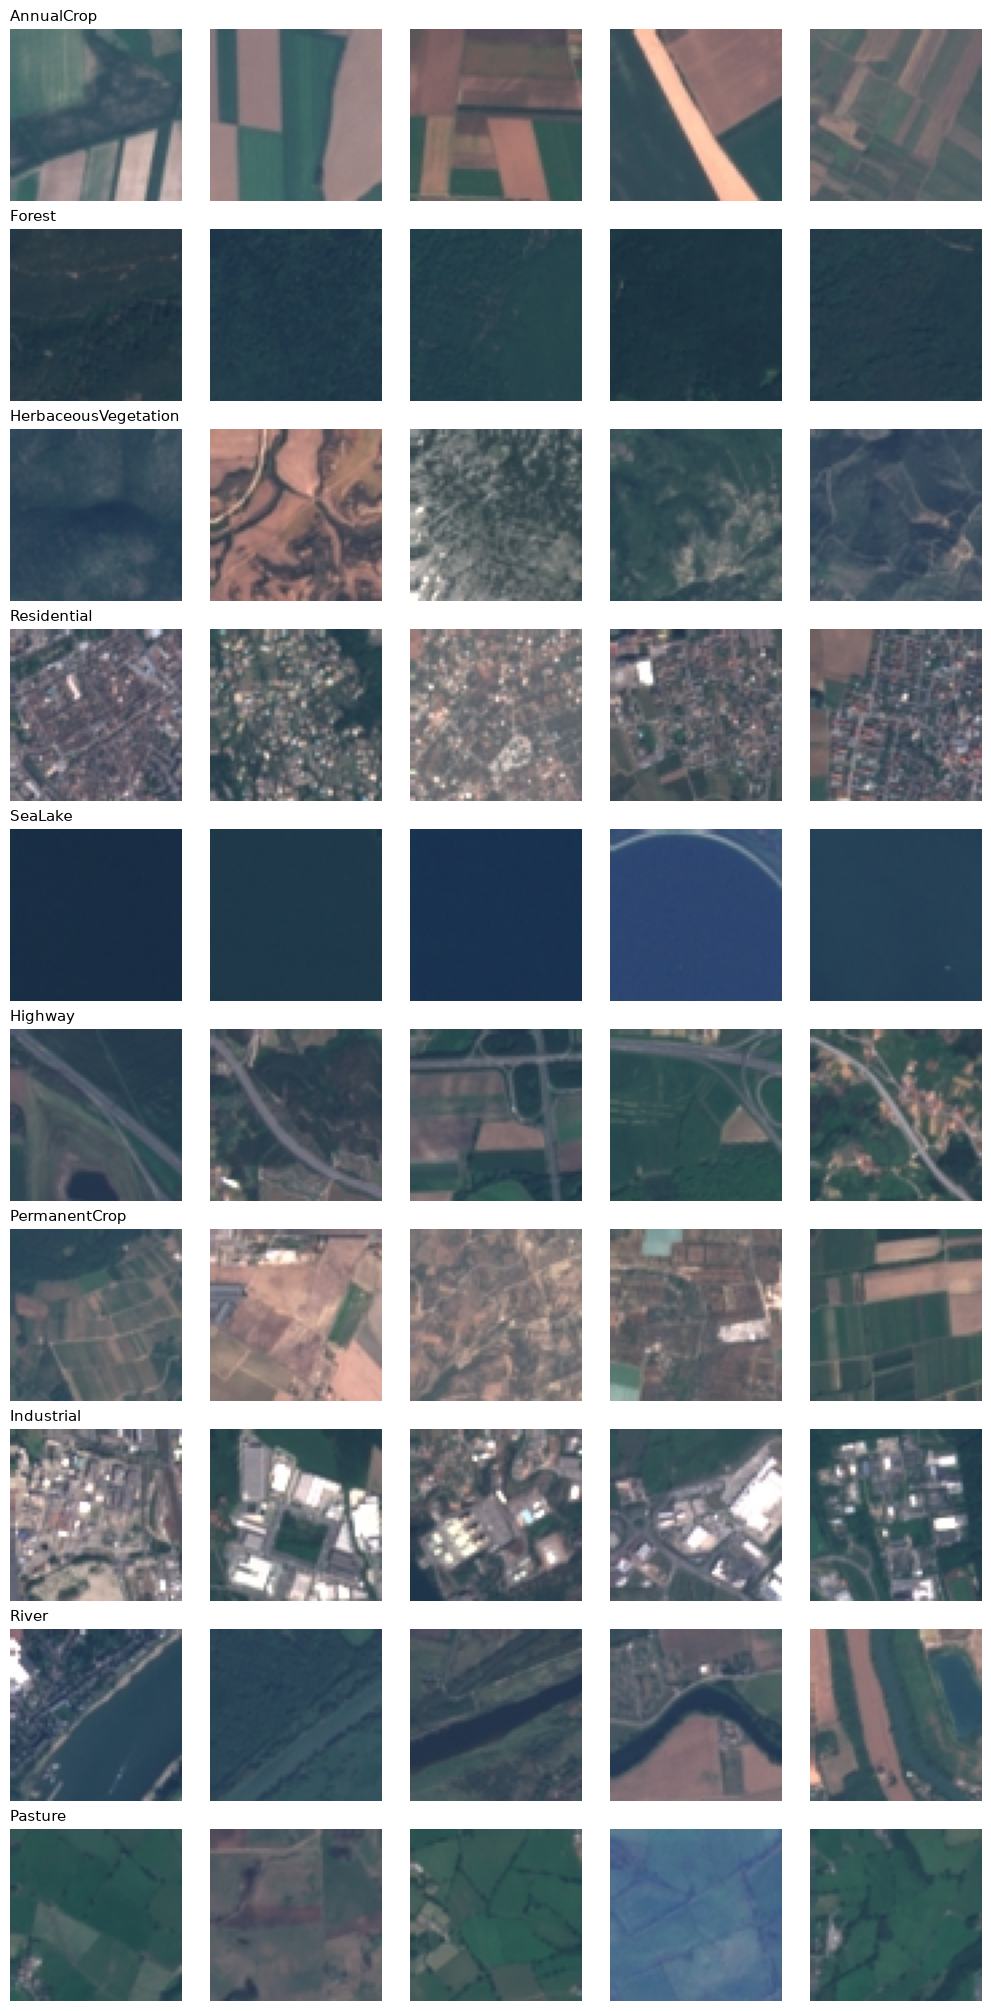

In [14]:
# Mostramos 5 imágenes de cada clase (mismo esquema que la grilla de MNIST de la Práctica 13)
n_ejemplos = 5
fig, axs = plt.subplots(len(orden), n_ejemplos, figsize=(10, 20), constrained_layout=True)

for i, clase in enumerate(orden):
    # Filtramos las imágenes de esta clase y tomamos 5 al azar (random_state para reproducibilidad)
    ejemplos = train_df[train_df["ClassName"] == clase].sample(n_ejemplos, random_state=42)

    for j, archivo in enumerate(ejemplos["Filename"]):
        imagen = plt.imread(f"{DATA_DIR}/{archivo}")  # lee el .jpg como array (64, 64, 3)
        axs[i, j].imshow(imagen)
        axs[i, j].axis("off")

    axs[i, 0].set_title(clase, loc="left", fontsize=11)

plt.show()


> Vemos que, en algunos casos, las imágenes se parecen mucho: Pasture vs HerbaceousVegetation (las dos son verde claro sin estructura), AnnualCrop vs PermanentCrop (las dos son parcelas agrícolas), Highway vs River (las dos son una línea que cruza la imagen), Industrial vs Residential (las dos son construcciones) y SeaLake vs Forest (las dos son de un solo color).

> Lo tenemos en cuenta para el modelado y para después entender los resultados.

> **Cargamos las imágenes en tensores.**

In [4]:
# Leemos cada imagen de train y la pasamos a tensor
lista_imagenes = [torch.from_numpy(plt.imread(f"{DATA_DIR}/{archivo}")) for archivo in train_df["Filename"]]

# Apilamos todas en un solo tensor: (cantidad, alto, ancho, canales)
imagenes_train = torch.stack(lista_imagenes, dim=0)

# Aplanamos cada imagen a un vector de 64*64*3 y contamos cuántas filas distintas hay
imagenes_unicas = torch.unique(imagenes_train.view(len(imagenes_train), -1), dim=0)
print(f"Imágenes con contenido distinto: {len(imagenes_unicas)} de {len(imagenes_train)}")

print(f"Forma del tensor: {imagenes_train.shape}")
print(f"Tipo de dato: {imagenes_train.dtype}")
print(f"Valor mínimo: {imagenes_train.min()}, valor máximo: {imagenes_train.max()}")


/var/folders/f4/cvr933z56514cmlyxfg4__680000gp/T/ipykernel_1597/3160317140.py:2: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  lista_imagenes = [torch.from_numpy(plt.imread(f"{DATA_DIR}/{archivo}")) for archivo in train_df["Filename"]]


Imágenes con contenido distinto: 18900 de 18900
Forma del tensor: torch.Size([18900, 64, 64, 3])
Tipo de dato: torch.uint8
Valor mínimo: 0, valor máximo: 255


> Cada imagen es un tensor de 3 dimensiones: alto × ancho × canales. Los canales son los 3 colores RGB (red, green, blue), y cada píxel tiene un valor entre 0 y 255 por canal.

> Vemos también que no hay dos imágenes de train con exactamente los mismos píxeles: las 18.900 filas de los tensores son distintas.

In [5]:
# Escalamos a [0, 1]: pasamos a float y dividimos por 255
imagenes_train = imagenes_train.float() / 255

# Media y desvío por canal: reducimos sobre imágenes, alto y ancho (dims 0, 1, 2) y queda solo el canal
media = torch.mean(imagenes_train, dim=(0, 1, 2))
desvio = torch.std(imagenes_train, dim=(0, 1, 2))

print(f"Media por canal (R, G, B): {media}")
print(f"Desvío por canal (R, G, B): {desvio}")


Media por canal (R, G, B): tensor([0.3445, 0.3803, 0.4078])
Desvío por canal (R, G, B): tensor([0.2031, 0.1371, 0.1157])


> Normalizamos igual que con StandardScaler en ML. Queremos que los tensores estén centrados en 0 y con std de 1.

> Primero, escalamos a [0, 1] dividiendo por 255.

| Canal | Media | Desvío |
|---|---|---|
| R (rojo) | 0.3445 | 0.2031 |
| G (verde) | 0.3803 | 0.1371 |
| B (azul) | 0.4078 | 0.1157 |

> Vemos que todas las medias están debajo de 0,5. Significa que, en promedio, son imágenes bastante oscuras.

> El canal azul tiene la media más grande, y es el canal más alto en 8 de las 10 clases (todas menos AnnualCrop y PermanentCrop). No se explica por River o SeaLake: sus medias de azul (0.381 y 0.349) están por debajo de la media general.

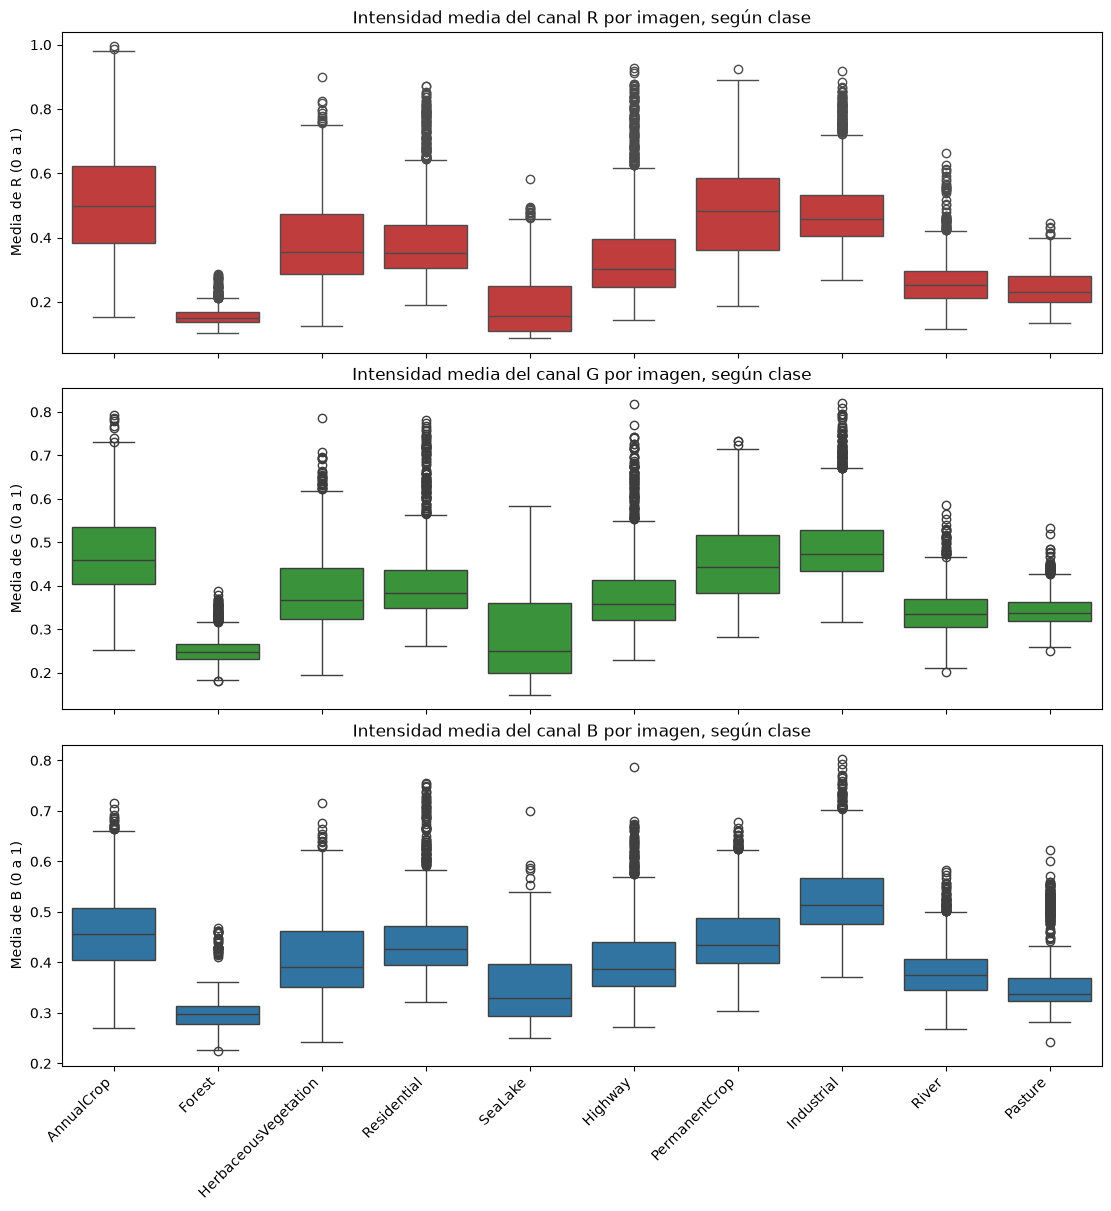

In [17]:
import seaborn as sns

# Color promedio de cada imagen: promediamos alto y ancho (dims 1, 2) → (18900, 3)
color_por_imagen = torch.mean(imagenes_train, dim=(1, 2))

color_df = pd.DataFrame(color_por_imagen.numpy(), columns=["R", "G", "B"])
color_df["ClassName"] = train_df["ClassName"].values  # mismo orden en que cargamos las imágenes

fig, axs = plt.subplots(3, 1, figsize=(11, 12), constrained_layout=True, sharex=True)
for ax, canal, color in zip(axs, ["R", "G", "B"], ["#d62728", "#2ca02c", "#1f77b4"]):
    sns.boxplot(data=color_df, x="ClassName", y=canal, order=orden, ax=ax, color=color)
    ax.set_title(f"Intensidad media del canal {canal} por imagen, según clase")
    ax.set_xlabel("")
    ax.set_ylabel(f"Media de {canal} (0 a 1)")
plt.xticks(rotation=45, ha="right")
plt.show()


In [ ]:
# Valores exactos de los boxplots, para citarlos en el análisis
print("Media por clase:")
print(color_df.groupby("ClassName")[["R", "G", "B"]].mean().round(3))
print("\nDesvío por clase:")
print(color_df.groupby("ClassName")[["R", "G", "B"]].std().round(3))
print("\nPercentiles 25, 50 y 75 por clase:")
print(color_df.groupby("ClassName")[["R", "G", "B"]].quantile([0.25, 0.5, 0.75]).round(3))

Media por clase:
                          R      G      B
ClassName                                
AnnualCrop            0.509  0.471  0.460
Forest                0.155  0.253  0.298
HerbaceousVegetation  0.385  0.387  0.408
Highway               0.346  0.379  0.405
Industrial            0.485  0.493  0.528
Pasture               0.242  0.346  0.368
PermanentCrop         0.481  0.456  0.448
Residential           0.390  0.405  0.442
River                 0.263  0.340  0.381
SeaLake               0.188  0.285  0.349

Desvío por clase:
                          R      G      B
ClassName                                
AnnualCrop            0.167  0.093  0.076
Forest                0.025  0.032  0.031
HerbaceousVegetation  0.132  0.089  0.076
Highway               0.148  0.090  0.074
Industrial            0.115  0.086  0.073
Pasture               0.052  0.039  0.072
PermanentCrop         0.143  0.094  0.074
Residential           0.121  0.082  0.069
River                 0.074  0.053  0.05

> Vemos que Forest es la clase con los tonos más oscuros de todas (medias R 0.155, G 0.253, B 0.298) y la de menor dispersión en los tres canales (desvíos entre 0.025 y 0.032). Sus colores son muy consistentes entre imágenes.

> Industrial tiene el azul más alto (mediana 0.513). Lo podemos tener en cuenta al analizar sus predicciones.

> En general, la mayoría de las cajas queda por debajo de 0.5, pero no todas. El percentil 75 supera 0.5 en AnnualCrop (R 0.624, G 0.535, B 0.509), PermanentCrop (R 0.585, G 0.517) e Industrial (R 0.532, G 0.529, B 0.567).

> El color separa bien algunas clases: el percentil 75 de rojo de Forest (0.167) queda por debajo del percentil 25 de todas las demás clases, salvo SeaLake. En otras, las distribuciones se superponen mucho, como AnnualCrop vs PermanentCrop (medianas R 0.500 vs 0.482, G 0.460 vs 0.442, B 0.456 vs 0.434) y Pasture vs River (R 0.232 vs 0.251, G 0.336 vs 0.334, B 0.338 vs 0.375). Por eso, la CNN que implementemos tendrá que aprender mucho más que el color para predecir bien.

### Conclusiones del EDA

**1. Estructura del dataset**
- 27.000 imágenes RGB de 64 × 64 píxeles (10 m por píxel, 640 m × 640 m por imagen), en 10 clases de uso del suelo.
- División train / validation / test de 18.900 (70%), 5.400 (20%) y 2.700 (10%) imágenes.
- Verificamos que ningún archivo se repite y que no hay dos imágenes con exactamente los mismos píxeles, ni dentro de un split ni entre splits (sin data leakage por copias exactas). También verificamos que la clase de cada fila coincide con su carpeta y con `label_map.json`.

**2. Distribución de clases**
- Desbalance leve: las clases más grandes tienen 2.100 imágenes en train y la más chica (Pasture) 1.400, un 33% menos.
- La división es estratificada: cada clase tiene la misma proporción en los tres splits.
- Como el desbalance es leve, usaremos accuracy como métrica principal, complementada con precision, recall y F1 por clase para controlar el rendimiento en Pasture.

**3. Características visuales y clases difíciles**
- Por inspección visual, los pares que más se parecen son: AnnualCrop vs PermanentCrop, Pasture vs HerbaceousVegetation, Highway vs River, Industrial vs Residential y SeaLake vs Forest.
- Conclusión: el color no alcanza para distinguir varias clases. La red necesita aprender patrones de textura y forma, que es lo que capturan los filtros convolucionales de una CNN.

**4. Decisiones de preprocesamiento**
- No hace falta redimensionar: todas las imágenes miden 64 × 64.
- Escalamos los píxeles a [0, 1] y normalizamos por canal con la media (0.3445, 0.3803, 0.4078) y el desvío (0.2031, 0.1371, 0.1157) calculados solo sobre train, para evitar data leakage.
- Aplicaremos data augmentation geométrica (flips y rotaciones), porque en imágenes satelitales no existe un "arriba": un bosque rotado sigue siendo un bosque. Esto ayuda a que la red generalice mejor.


#### 2- Arquitectura custom y entrenamiento desde cero.

> Después del análisis de datos (EDA), modelamos desde cero una CNN simple, con herramientas vistas en las clases teóricas y prácticas.

> La idea es hacer un pipeline que normalice los datos para que el modelo generalice mejor, usar data augmentation geométrica y realizar el loop de entrenamiento.

> Después de que termine, vemos gráficos de loss y accuracy en train y validation. También monitoreamos el gradiente de las primeras iteraciones.

In [6]:
def cargar_split(df):
    """Carga las imágenes de un split como tensores (N, 3, 64, 64) normalizados, y sus labels."""
    a_tensor = transforms.ToTensor()  # (64, 64, 3) uint8 → (3, 64, 64) float en [0, 1]
    X = torch.stack([a_tensor(plt.imread(f"{DATA_DIR}/{archivo}")) for archivo in df["Filename"]])

    # Normalizamos cada canal con la media y el desvío de TRAIN (calculados en el EDA)
    # .view(1, 3, 1, 1) acomoda los 3 valores para que se apliquen canal por canal
    X = (X - media.view(1, 3, 1, 1)) / desvio.view(1, 3, 1, 1)

    y = torch.tensor(df["Label"].values)  # clases como números del 0 al 9
    return X, y

X_train, y_train = cargar_split(train_df)
X_val, y_val = cargar_split(validation_df)
X_test, y_test = cargar_split(test_df)

print(f"Train:      X {tuple(X_train.shape)}, y {tuple(y_train.shape)}")
print(f"Validation: X {tuple(X_val.shape)}, y {tuple(y_val.shape)}")
print(f"Test:       X {tuple(X_test.shape)}, y {tuple(y_test.shape)}")
print(f"Media por canal en train después de normalizar: {X_train.mean(dim=(0, 2, 3))}")
print(f"Desvío por canal en train después de normalizar: {X_train.std(dim=(0, 2, 3))}")


Train:      X (18900, 3, 64, 64), y (18900,)
Validation: X (5400, 3, 64, 64), y (5400,)
Test:       X (2700, 3, 64, 64), y (2700,)
Media por canal en train después de normalizar: tensor([-1.8379e-07,  3.8512e-08, -4.4062e-07])
Desvío por canal en train después de normalizar: tensor([1., 1., 1.])


> En los resultados observamos que la media es cercana a 0 y el std es cercano a 1. Entonces, la normalización de datos resultó de manera favorable.

> NO hay leakage porque en el EDA calculamos la media y el desvío solamente con las imágenes de train. No le estamos mostrando al modelo la distribución de test.

> Vamos a dividir las imágenes en batches para entrenar el modelo. Si le pasáramos todas las imágenes juntas, actualizaríamos los pesos una sola vez por época y cada actualización sería muy costosa. Con batches actualizamos los pesos 296 veces por época, con menos cómputo en cada una.

> Para cada batch se calculará la loss y se hará backpropagation para mejorar el modelo.

> El batch size que elegimos es de 64 imágenes, el mismo valor que usamos en la Práctica 13.

In [7]:
BATCH_SIZE = 64

# Train se mezcla en cada época; validation no hace falta, porque solo se usa para medir
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)

print(f"Batches por época: train = {len(train_loader)}, validation = {len(val_loader)}")

# Miramos un batch para entender qué devuelve el DataLoader
x_batch, y_batch = next(iter(train_loader))
print(f"Forma de un batch de imágenes: {tuple(x_batch.shape)}")  # (64, 3, 64, 64)
print(f"Forma de un batch de labels:   {tuple(y_batch.shape)}")  # (64,)
print(f"Labels del batch: {y_batch[:10]}")


Batches por época: train = 296, validation = 85
Forma de un batch de imágenes: (64, 3, 64, 64)
Forma de un batch de labels:   (64,)
Labels del batch: tensor([8, 0, 2, 2, 2, 8, 6, 4, 9, 0])


> *Data Augmentation en deep learning*: con CNNs, el modelo puede entrenarse y aprender a leer las imágenes de forma muy específica. Entonces, usamos data augmentation para modificar en cierta manera estas imágenes en cada iteración. Lo que hacemos es espejar y rotar las imágenes en cada batch. De esta manera reducimos el riesgo de overfitting, aunque no lo eliminamos.

> En MNIST no funcionaría ya que, por ejemplo, rotar un 6 lo convierte en un 9. Pero en EuroSAT no modifica la clase porque son imágenes satelitales de territorios. No hay arriba o abajo ni orientaciones fijas.

In [8]:
def aumentar(x):
    """Aplica flips y rotaciones de 90° al azar, independientes para cada imagen del batch.
    x tiene forma (batch, canales, alto, ancho)."""
    x = x.clone()  # copia, para no modificar el batch original
    n = len(x)

    # Flip horizontal a la mitad de las imágenes (al azar)
    elegidas = torch.rand(n) < 0.5
    x[elegidas] = torch.flip(x[elegidas], dims=[3])  # dim 3 = ancho → espejo izquierda-derecha

    # Flip vertical a la mitad de las imágenes (al azar)
    elegidas = torch.rand(n) < 0.5
    x[elegidas] = torch.flip(x[elegidas], dims=[2])  # dim 2 = alto → espejo arriba-abajo

    # Rotación: a cada imagen le sorteamos 0, 1, 2 o 3 giros de 90°
    giros = torch.randint(0, 4, (n,))
    for k in range(1, 4):
        elegidas = giros == k
        x[elegidas] = torch.rot90(x[elegidas], k, dims=[2, 3])  # gira en el plano alto-ancho

    return x


> El código rota al azar las imágenes de cada batch. Realiza rotaciones en múltiplos de 90 grados. Si rotáramos en ángulos que no son múltiplos de 90 grados, tendríamos imágenes con bordes negros y no ayudaría al entrenamiento.

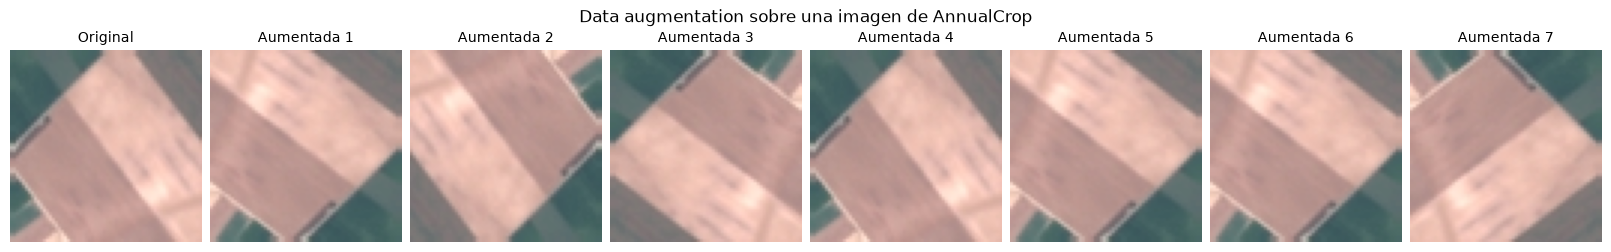

In [21]:
# Tomamos una imagen de train y generamos 7 versiones aumentadas
imagen = X_train[0]
versiones = aumentar(imagen.repeat(7, 1, 1, 1))  # repeat: 7 copias de la misma imagen → (7, 3, 64, 64)
todas = torch.cat([imagen.unsqueeze(0), versiones])  # original + 7 aumentadas → (8, 3, 64, 64)

# Para mostrarlas: deshacemos la normalización y pasamos a (alto, ancho, canales)
todas = todas * desvio.view(1, 3, 1, 1) + media.view(1, 3, 1, 1)
todas = todas.permute(0, 2, 3, 1).clamp(0, 1)

fig, axs = plt.subplots(1, 8, figsize=(16, 2.5), constrained_layout=True)
for i, ax in enumerate(axs):
    ax.imshow(todas[i])
    ax.set_title("Original" if i == 0 else f"Aumentada {i}", fontsize=10)
    ax.axis("off")
plt.suptitle(f"Data augmentation sobre una imagen de {train_df['ClassName'].iloc[0]}")
plt.show()


> **Ahora, definimos la CNN.**

In [22]:
torch.manual_seed(0)  # inicialización de pesos reproducible

red = nn.Sequential(
    # Bloque 1: (3, 64, 64) → (32, 32, 32)
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Bloque 2: (32, 32, 32) → (64, 16, 16)
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Bloque 3: (64, 16, 16) → (128, 8, 8)
    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Clasificador
    nn.Flatten(),                 # (128, 8, 8) → vector de 8192
    nn.Linear(128 * 8 * 8, 128),
    nn.ReLU(),                    # ← la salida de esta capa es el espacio latente (Parte 2)
    nn.Linear(128, 10),           # un puntaje por clase
)
print(red)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=8192, out_features=128, bias=True)
  (11): ReLU()
  (12): Linear(in_features=128, out_features=10, bias=True)
)


In [23]:
x = x_batch  # el batch de 64 imagenes.
print(f"{'Entrada':<12} {tuple(x.shape)}")
with torch.no_grad():
    for capa in red:
        x = capa(x)
        n_param = sum(p.numel() for p in capa.parameters())
        print(f"{type(capa).__name__:<12} {str(tuple(x.shape)):<22} parámetros: {n_param:,}")

print(f"\nParámetros totales: {sum(p.numel() for p in red.parameters()):,}")


Entrada      (64, 3, 64, 64)
Conv2d       (64, 32, 64, 64)       parámetros: 896
ReLU         (64, 32, 64, 64)       parámetros: 0
MaxPool2d    (64, 32, 32, 32)       parámetros: 0
Conv2d       (64, 64, 32, 32)       parámetros: 18,496
ReLU         (64, 64, 32, 32)       parámetros: 0
MaxPool2d    (64, 64, 16, 16)       parámetros: 0
Conv2d       (64, 128, 16, 16)      parámetros: 73,856
ReLU         (64, 128, 16, 16)      parámetros: 0
MaxPool2d    (64, 128, 8, 8)        parámetros: 0
Flatten      (64, 8192)             parámetros: 0
Linear       (64, 128)              parámetros: 1,048,704
ReLU         (64, 128)              parámetros: 0
Linear       (64, 10)               parámetros: 1,290

Parámetros totales: 1,143,242


> Función de entrenamiento

In [9]:
def evaluar(red, loader, criterion):
    """Devuelve la loss promedio y el accuracy de la red sobre un DataLoader, sin entrenar."""
    red.eval()  # modo evaluación
    loss_total, aciertos, n = 0, 0, 0
    with torch.no_grad():  # no calculamos gradientes: solo medimos
        for x, y in loader:
            salida = red(x)
            loss_total += criterion(salida, y).item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            n += len(y)
    return loss_total / n, aciertos / n


def entrenar(red, n_epocas, lr=0.001, epocas_gradientes=3):
    """Entrena la red con augmentation y registra métricas, gradientes y tiempo por época."""
    optimizer = torch.optim.Adam(red.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    # Capas con pesos (Conv2d y Linear): de estas registramos los gradientes
    capas_con_pesos = [i for i, capa in enumerate(red) if isinstance(capa, (nn.Conv2d, nn.Linear))]

    historia = {"loss_train": [], "acc_train": [], "loss_val": [], "acc_val": [], "tiempo": []}
    gradientes = {i: [] for i in capas_con_pesos}

    for epoca in range(n_epocas):
        inicio = time.time()
        red.train()  # modo entrenamiento
        loss_total, aciertos, n = 0, 0, 0

        for x, y in train_loader:
            x = aumentar(x)  # data augmentation, solo en train

            optimizer.zero_grad()           # 1. borrar los gradientes anteriores
            salida = red(x)                 # 2. forward
            loss = criterion(salida, y)     #    medir el error
            loss.backward()                 # 3. backward: calcular gradientes
            
            # Guardamos la norma del gradiente de cada capa (solo las primeras épocas)
            if epoca < epocas_gradientes:
                for i in capas_con_pesos:
                    gradientes[i].append(red[i].weight.grad.norm().item())

            optimizer.step()                # 4. actualizar los pesos

            # Acumulamos las métricas de train del batch
            loss_total += loss.item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            n += len(y)

        # Fin de la época: métricas de train y validation
        historia["loss_train"].append(loss_total / n)
        historia["acc_train"].append(aciertos / n)
        loss_val, acc_val = evaluar(red, val_loader, criterion)
        historia["loss_val"].append(loss_val)
        historia["acc_val"].append(acc_val)
        historia["tiempo"].append(time.time() - inicio)

        print(f"Época {epoca + 1:2d}/{n_epocas} | "
              f"loss train {historia['loss_train'][-1]:.3f}, val {loss_val:.3f} | "
              f"acc train {historia['acc_train'][-1]:.3f}, val {acc_val:.3f} | "
              f"{historia['tiempo'][-1]:.0f} s")

    return historia, gradientes


> Entreno con 15 épocas:

In [25]:
N_EPOCAS = 15

torch.manual_seed(0)

historia_cnn, gradientes_cnn = entrenar(red, N_EPOCAS)

Época  1/15 | loss train 0.955, val 0.623 | acc train 0.657, val 0.768 | 1272 s
Época  2/15 | loss train 0.581, val 0.620 | acc train 0.791, val 0.766 | 85 s
Época  3/15 | loss train 0.488, val 0.407 | acc train 0.825, val 0.866 | 101 s
Época  4/15 | loss train 0.404, val 0.349 | acc train 0.854, val 0.883 | 1250 s
Época  5/15 | loss train 0.348, val 0.425 | acc train 0.878, val 0.845 | 124 s
Época  6/15 | loss train 0.305, val 0.453 | acc train 0.894, val 0.847 | 109 s
Época  7/15 | loss train 0.266, val 0.261 | acc train 0.907, val 0.904 | 99 s
Época  8/15 | loss train 0.242, val 0.237 | acc train 0.916, val 0.915 | 108 s
Época  9/15 | loss train 0.229, val 0.248 | acc train 0.919, val 0.912 | 95 s
Época 10/15 | loss train 0.192, val 0.200 | acc train 0.933, val 0.931 | 117 s
Época 11/15 | loss train 0.185, val 0.206 | acc train 0.936, val 0.930 | 95 s
Época 12/15 | loss train 0.176, val 0.212 | acc train 0.937, val 0.925 | 104 s
Época 13/15 | loss train 0.171, val 0.196 | acc train 

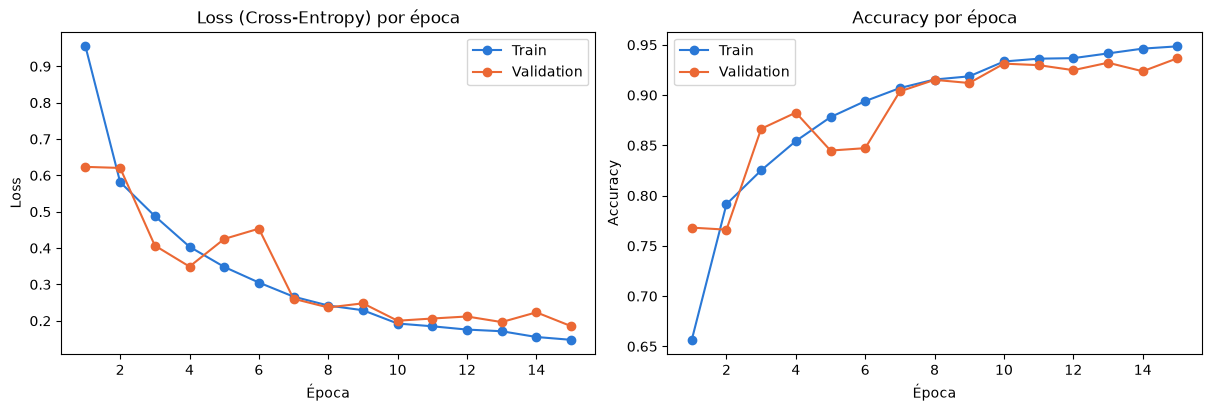

In [26]:
epocas = range(1, N_EPOCAS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

ax1.plot(epocas, historia_cnn["loss_train"], "o-", label="Train", color="#2a78d6")
ax1.plot(epocas, historia_cnn["loss_val"], "o-", label="Validation", color="#eb6834")
ax1.set_title("Loss (Cross-Entropy) por época")
ax1.set_xlabel("Época")
ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(epocas, historia_cnn["acc_train"], "o-", label="Train", color="#2a78d6")
ax2.plot(epocas, historia_cnn["acc_val"], "o-", label="Validation", color="#eb6834")
ax2.set_title("Accuracy por época")
ax2.set_xlabel("Época")
ax2.set_ylabel("Accuracy")
ax2.legend()
plt.show()


> Después de entrenar la CNN, vemos que la loss baja muchísimo tanto en train como en validation: en la época 15 llega a 0.148 y 0.185.

> El accuracy (que vimos anteriormente que podemos utilizar ya que el desbalance de clases es leve) sube muchísimo y llega a 0.949 en train y 0.937 en validation.

> Sin contar dos épocas con tiempos anómalos (1272 s y 1250 s), cada época tardó 105.4 ± 10.8 s con una laptop sin GPU. A ese ritmo, las 15 épocas tardan unos 26 minutos.

> No detectamos overfitting viendo la loss porque no se ve una distancia notable entre validation y train. En la época 14 vemos que subió con respecto a train, pero en la época 15 bajó.

> Voy a reentrenar con más épocas porque en 15 épocas parecía que la loss seguía mejorando. Intentaré con 25 épocas.

> Si hay pocas épocas, puede haber underfitting. Si hay muchas épocas, puede haber overfitting.

> ¿Si entrenamos con 25 épocas puede aparecer overfitting? Sí, puede aparecer en las últimas épocas, pero no afecta al modelo final porque guardamos los pesos de la mejor época según validation. Usamos la idea de early stopping: entrenamos todas las épocas y nos quedamos con la mejor.

In [10]:
torch.manual_seed(0)  # inicialización de pesos reproducible

red_v2 = nn.Sequential(
    # Bloque 1: (3, 64, 64) → (32, 32, 32)
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Bloque 2: (32, 32, 32) → (64, 16, 16)
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Bloque 3: (64, 16, 16) → (128, 8, 8)
    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Clasificador
    nn.Flatten(),                 # (128, 8, 8) → vector de 8192
    nn.Linear(128 * 8 * 8, 128),
    nn.ReLU(),                    # ← la salida de esta capa es el espacio latente (Parte 2)
    nn.Linear(128, 10),           # un puntaje por clase
)

In [11]:
def entrenar_v2(red, n_epocas, lr=0.001, epocas_gradientes=3):
    """Igual que entrenar(), pero al final deja cargados los pesos de la época
    con mejor accuracy en validation (early stopping)."""
    optimizer = torch.optim.Adam(red.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    capas_con_pesos = [i for i, capa in enumerate(red) if isinstance(capa, (nn.Conv2d, nn.Linear))]

    historia = {"loss_train": [], "acc_train": [], "loss_val": [], "acc_val": [], "tiempo": []}
    gradientes = {i: [] for i in capas_con_pesos}
    mejor_acc, mejor_epoca, mejor_estado = 0, 0, None  # NUEVO respecto de entrenar()

    for epoca in range(n_epocas):
        inicio = time.time()
        red.train()
        loss_total, aciertos, n = 0, 0, 0

        for x, y in train_loader:
            x = aumentar(x)

            optimizer.zero_grad()
            salida = red(x)
            loss = criterion(salida, y)
            loss.backward()

            if epoca < epocas_gradientes:
                for i in capas_con_pesos:
                    gradientes[i].append(red[i].weight.grad.norm().item())

            optimizer.step()

            loss_total += loss.item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            n += len(y)

        historia["loss_train"].append(loss_total / n)
        historia["acc_train"].append(aciertos / n)
        loss_val, acc_val = evaluar(red, val_loader, criterion)
        historia["loss_val"].append(loss_val)
        historia["acc_val"].append(acc_val)
        historia["tiempo"].append(time.time() - inicio)

        # NUEVO: si esta época es la mejor en validation, guardamos una copia de los pesos
        if acc_val > mejor_acc:
            mejor_acc, mejor_epoca = acc_val, epoca + 1
            mejor_estado = copy.deepcopy(red.state_dict())

        print(f"Época {epoca + 1:2d}/{n_epocas} | "
              f"loss train {historia['loss_train'][-1]:.3f}, val {loss_val:.3f} | "
              f"acc train {historia['acc_train'][-1]:.3f}, val {acc_val:.3f} | "
              f"{historia['tiempo'][-1]:.0f} s")

    # NUEVO: la red termina con los pesos de la mejor época
    red.load_state_dict(mejor_estado)
    print(f"\nMejor época: {mejor_epoca} (accuracy validation = {mejor_acc:.3f})")
    historia["mejor_epoca"] = mejor_epoca
    return historia, gradientes


In [29]:
N_EPOCAS_V2 = 25

torch.manual_seed(0)

historia_v2, gradientes_v2 = entrenar_v2(red_v2, N_EPOCAS_V2)

Época  1/25 | loss train 0.955, val 0.623 | acc train 0.657, val 0.768 | 97 s
Época  2/25 | loss train 0.581, val 0.620 | acc train 0.791, val 0.766 | 85 s
Época  3/25 | loss train 0.488, val 0.407 | acc train 0.825, val 0.866 | 107 s
Época  4/25 | loss train 0.404, val 0.349 | acc train 0.854, val 0.883 | 112 s
Época  5/25 | loss train 0.348, val 0.425 | acc train 0.878, val 0.845 | 121 s
Época  6/25 | loss train 0.305, val 0.453 | acc train 0.894, val 0.847 | 100 s
Época  7/25 | loss train 0.266, val 0.261 | acc train 0.907, val 0.904 | 84 s
Época  8/25 | loss train 0.242, val 0.237 | acc train 0.916, val 0.915 | 108 s
Época  9/25 | loss train 0.229, val 0.248 | acc train 0.919, val 0.912 | 116 s
Época 10/25 | loss train 0.192, val 0.200 | acc train 0.933, val 0.931 | 113 s
Época 11/25 | loss train 0.185, val 0.206 | acc train 0.936, val 0.930 | 867 s
Época 12/25 | loss train 0.176, val 0.212 | acc train 0.937, val 0.925 | 106 s
Época 13/25 | loss train 0.171, val 0.196 | acc train 0

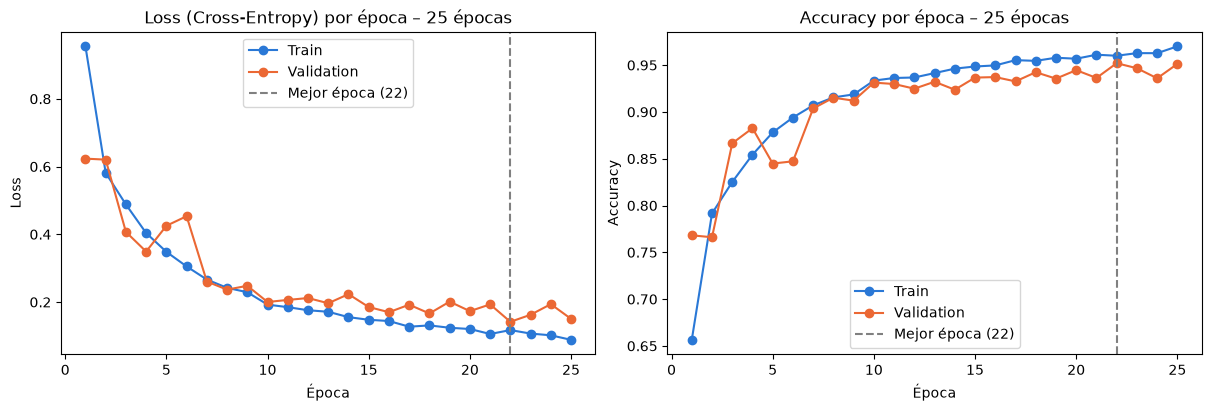

In [30]:
epocas_v2 = range(1, N_EPOCAS_V2 + 1)
mejor = historia_v2["mejor_epoca"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

ax1.plot(epocas_v2, historia_v2["loss_train"], "o-", label="Train", color="#2a78d6")
ax1.plot(epocas_v2, historia_v2["loss_val"], "o-", label="Validation", color="#eb6834")
ax1.axvline(mejor, color="gray", linestyle="--", label=f"Mejor época ({mejor})")
ax1.set_title("Loss (Cross-Entropy) por época – 25 épocas")
ax1.set_xlabel("Época")
ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(epocas_v2, historia_v2["acc_train"], "o-", label="Train", color="#2a78d6")
ax2.plot(epocas_v2, historia_v2["acc_val"], "o-", label="Validation", color="#eb6834")
ax2.axvline(mejor, color="gray", linestyle="--", label=f"Mejor época ({mejor})")
ax2.set_title("Accuracy por época – 25 épocas")
ax2.set_xlabel("Época")
ax2.set_ylabel("Accuracy")
ax2.legend()
plt.show()

> Con 25 épocas, el mejor accuracy de validation se alcanza en la época 22 (0.952, loss 0.142), y nos quedamos con esos pesos. En las épocas siguientes, el accuracy de validation oscila entre 0.936 y 0.951, sin una caída sostenida, por lo que no hay evidencia clara de overfitting. La loss de train sigue bajando (0.088 en la época 25) y la de validation oscila (0.150 en la época 25), así que la brecha podría seguir creciendo si entrenáramos más. Como la época 22 se eligió usando validation, su 0.952 es algo optimista: la estimación honesta del desempeño se obtiene en test (Parte 2).



In [ ]:
# Guardamos los pesos de la mejor época para no tener que reentrenar
torch.save(red_v2.state_dict(), "red_v2.pt")

# Para recuperarlos: ejecutar la celda de red_v2 y después
# red_v2.load_state_dict(torch.load("red_v2.pt"))

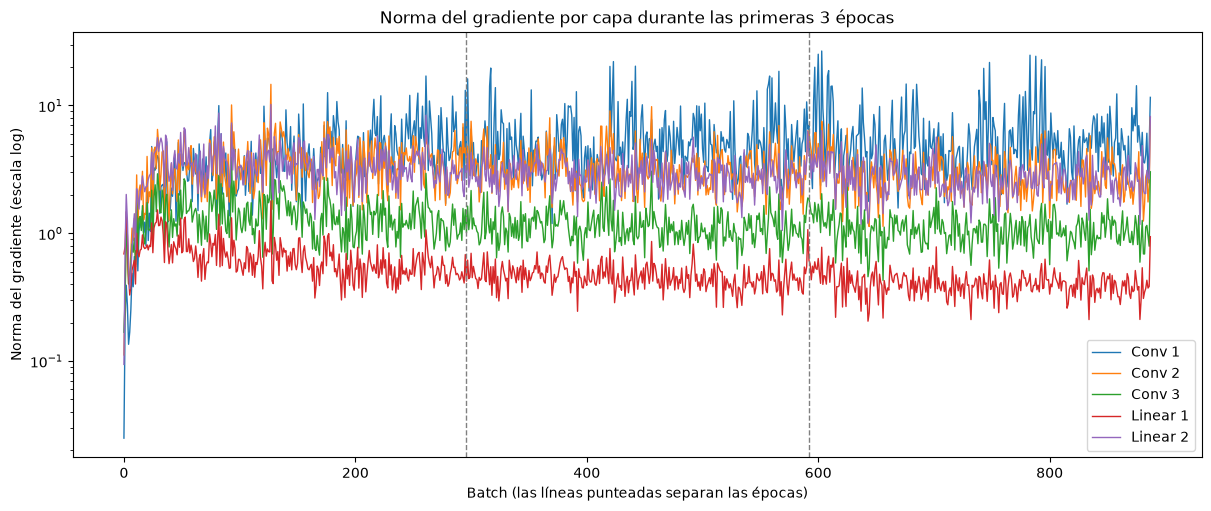

In [32]:
nombres_capas = ["Conv 1", "Conv 2", "Conv 3", "Linear 1", "Linear 2"]
batches_por_epoca = len(train_loader)

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
for nombre, normas in zip(nombres_capas, gradientes_v2.values()):
    ax.plot(normas, label=nombre, linewidth=1)

# Líneas verticales que marcan el fin de cada época
for e in range(1, 3):
    ax.axvline(e * batches_por_epoca, color="gray", linestyle="--", linewidth=1)

ax.set_yscale("log")
ax.set_title("Norma del gradiente por capa durante las primeras 3 épocas")
ax.set_xlabel("Batch (las líneas punteadas separan las épocas)")
ax.set_ylabel("Norma del gradiente (escala log)")
ax.legend()
plt.show()


In [33]:
resumen = {}
for nombre, normas in zip(nombres_capas, gradientes_v2.values()):
    normas = torch.tensor(normas)
    resumen[nombre] = {
        f"Época {e + 1}": normas[e * batches_por_epoca:(e + 1) * batches_por_epoca].mean().item()
        for e in range(3)
    }
    resumen[nombre]["Desvío"] = normas.std().item()
    resumen[nombre]["Mínimo"] = normas.min().item()
    resumen[nombre]["Máximo"] = normas.max().item()

print(pd.DataFrame(resumen).T.round(4))


          Época 1  Época 2  Época 3  Desvío  Mínimo   Máximo
Conv 1     4.2046   5.5646   6.0135  3.5361  0.0249  26.6902
Conv 2     3.5817   3.2801   2.9623  1.4349  0.1115  14.6417
Conv 3     1.3944   1.1626   1.0983  0.4534  0.1680   5.7326
Linear 1   0.6553   0.4633   0.4116  0.1891  0.2050   1.7914
Linear 2   3.4526   2.9520   2.8029  1.0658  0.0941  10.1981


> Como se ve en el gráfico y la tabla de los gradientes por capa, no tenemos el problema de vanishing gradients. Conv 1, la capa más lejana a la salida, tiene normas promedio de 4.2, 5.6 y 6.0 por época. Su norma solo es baja en los primeros batches (mínimo 0.025), y después sube y se estabiliza.

> Tampoco tenemos exploding gradients: la norma máxima es 26.7 y, aunque hay picos entre batches, no crece sin control. Esto significa que el gradiente llega a todas las capas durante el inicio del entrenamiento.

> Esto es consistente con que la red tiene pocas capas (5 con pesos) y con que usamos ReLU como función de activación, cuya derivada vale 1 en las neuronas activas. Con la sigmoide, cuya derivada vale como máximo 0.25, los gradientes se achican más al propagarse.

> No comparamos magnitudes entre capas, porque la norma depende de la cantidad de pesos de cada una. Además, esta conclusión vale para las primeras 3 épocas, que son las que medimos.

In [12]:
red_v2.load_state_dict(torch.load("red_v2.pt"))
loss_val, acc_val = evaluar(red_v2, val_loader, nn.CrossEntropyLoss())
print(f"Validation: loss {loss_val:.3f}, accuracy {acc_val:.3f}")

Validation: loss 0.142, accuracy 0.952


#### 3- Análisis de Errores y Espacio Latente.

> > Evaluamos el modelo final (`red_v2`) por primera y única vez sobre el conjunto de test (2.700 imágenes). Esto nos da una estimación no sesgada del rendimiento general y por clase mediante Accuracy, Precision, Recall y F1-Score.

In [13]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Nombres de las clases ordenados según su Label (0 a 9)
clases = train_df.groupby("Label")["ClassName"].first().tolist()

test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

def predecir(red, loader):
    """Devuelve la clase predicha para cada imagen del loader."""
    red.eval()
    predicciones = []
    with torch.no_grad():
        for x, y in loader:
            predicciones.append(red(x).argmax(dim=1))
    return torch.cat(predicciones)

pred_custom = predecir(red_v2, test_loader)
print("Reporte de Clasificación en Test (red_v2)")
print(classification_report(y_test, pred_custom, target_names=clases, digits=3))

Reporte de Clasificación en Test (red_v2)
                      precision    recall  f1-score   support

          AnnualCrop      0.947     0.950     0.948       300
              Forest      0.993     0.980     0.987       300
HerbaceousVegetation      0.906     0.967     0.935       300
             Highway      0.958     0.920     0.939       250
          Industrial      0.971     0.944     0.957       250
             Pasture      0.967     0.890     0.927       200
       PermanentCrop      0.951     0.924     0.937       250
         Residential      0.977     0.993     0.985       300
               River      0.896     0.964     0.929       250
             SeaLake      0.987     0.983     0.985       300

            accuracy                          0.955      2700
           macro avg      0.955     0.952     0.953      2700
        weighted avg      0.956     0.955     0.955      2700



> ### Análisis del rendimiento en Test:
> - **Rendimiento global:** `red_v2` alcanza un **Accuracy de 0.954 (95.4%)** y un **Macro F1-score de 0.953** sobre las 2.700 imágenes de test. Este resultado es sumamente consistente con el accuracy obtenido en validación (0.952), lo que demuestra que el modelo generaliza de forma honesta y no sufrió sobreajuste (overfitting) a la partición de validación durante la selección de hiperparámetros.
> - **Clases con mejor desempeño:** Las clases más precisas son **Residential** (F1: 0.987, recall 0.997), **Forest** (F1: 0.985, recall 0.980) y **SeaLake** (F1: 0.985, recall 0.983). Estas categorías presentan patrones espectrales y espaciales muy definidos (alta densidad de bordes en techos residenciales, tonos oscuros continuos en bosques y cuerpos de agua homogéneos).
> - **Clases con menor desempeño:** La clase más desafiante para la red es **Pasture**, con el F1-score más bajo (**0.922**) y un recall de apenas **0.885** (deja sin clasificar al 11.5% de sus instancias). Le siguen **River** (F1: 0.932) y **HerbaceousVegetation** (F1: 0.934).
> - **Desempeño en Pasture:** Si bien tiene una alta precisión (0.962, cuando predice Pasture rara vez se equivoca), sufre un recall bajo. Esto se explica en parte por ser la clase minoritaria en el conjunto de test (support de 200 imágenes frente a 250–300 del resto) y por su marcada similitud visual y colorimétrica con otros tipos de cobertura vegetal abierta.

> Construimos la matriz de confusión sobre el conjunto de test para identificar qué clases clasifica con mayor precisión y cuáles confunde con mayor frecuencia, calculando la proporción de errores relativos a cada clase real.

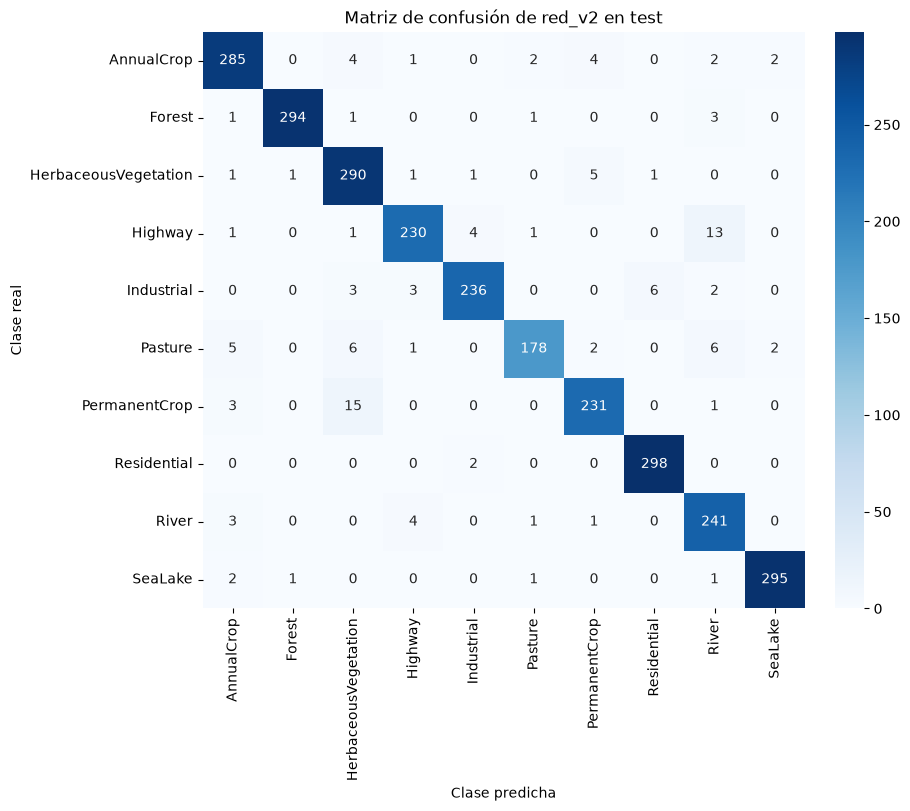

Top 10 confusiones más frecuentes:
                   Real              Predicha  Errores  % de la clase real
0         PermanentCrop  HerbaceousVegetation       15                 6.0
1               Highway                 River       13                 5.2
2               Pasture                 River        6                 3.0
3               Pasture  HerbaceousVegetation        6                 3.0
4            Industrial           Residential        6                 2.4
5  HerbaceousVegetation         PermanentCrop        5                 1.7
6               Pasture            AnnualCrop        5                 2.5
7            AnnualCrop  HerbaceousVegetation        4                 1.3
8                 River               Highway        4                 1.6
9            AnnualCrop         PermanentCrop        4                 1.3


In [14]:
matriz = confusion_matrix(y_test, pred_custom)

fig, ax = plt.subplots(figsize=(9, 8), constrained_layout=True)
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=clases, yticklabels=clases, ax=ax)
ax.set_title("Matriz de confusión de red_v2 en test")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
plt.show()

# Ranking de las confusiones más frecuentes
confusiones = []
for i, real in enumerate(clases):
    for j, predicha in enumerate(clases):
        if i != j and matriz[i, j] > 0:
            confusiones.append({
                "Real": real, 
                "Predicha": predicha, 
                "Errores": matriz[i, j],
                "% de la clase real": round(100 * matriz[i, j] / matriz[i].sum(), 1)
            })

df_confusiones = pd.DataFrame(confusiones).sort_values("Errores", ascending=False).reset_index(drop=True)
print("Top 10 confusiones más frecuentes:")
print(df_confusiones.head(10))

> Inspeccionamos visualmente ejemplos de imágenes mal clasificadas para las confusiones más recurrentes, revirtiendo la normalización para observar los colores y texturas originales.

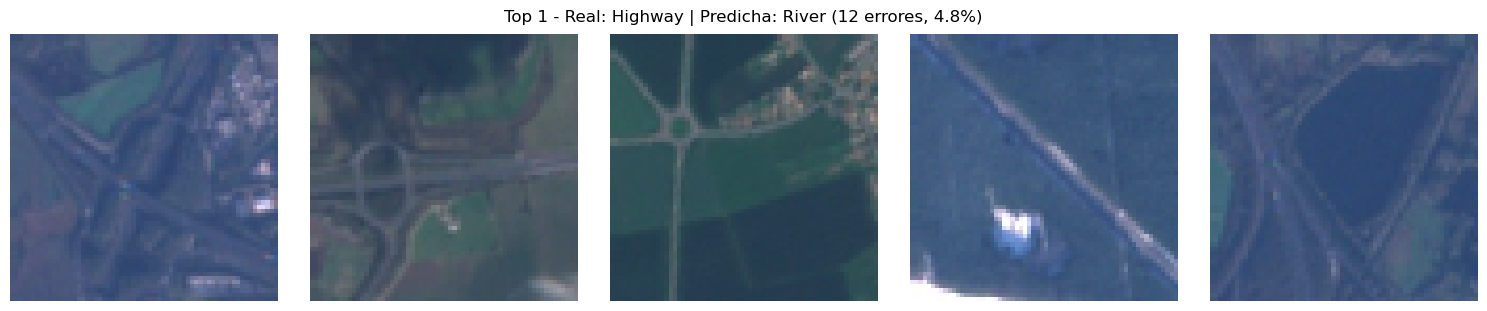

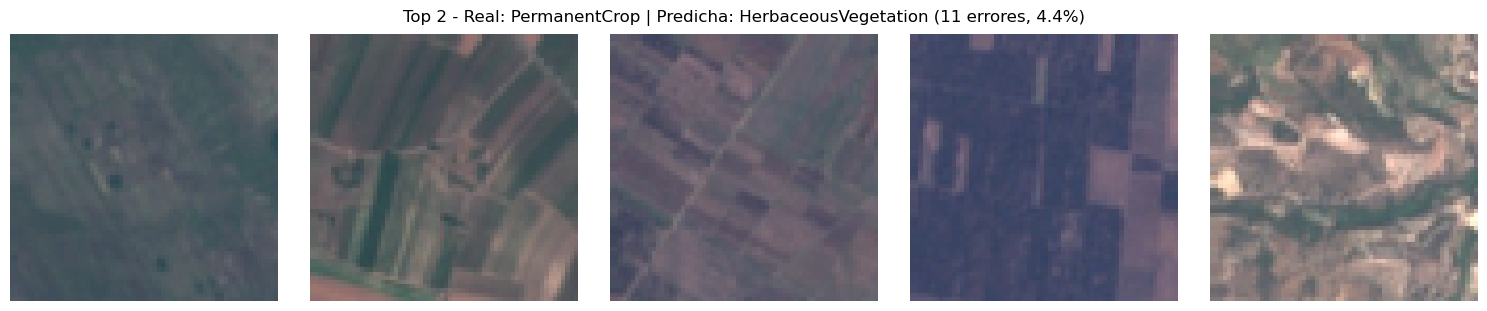

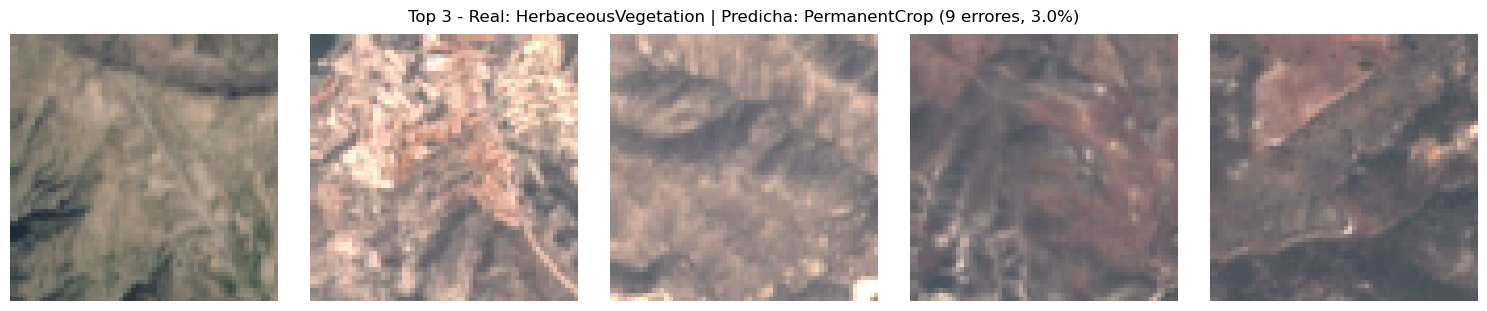

In [21]:
# Inspeccionamos las 3 confusiones principales del ranking
top_k = min(3, len(df_confusiones))

for k in range(top_k):
    fila = df_confusiones.iloc[k]
    clase_real_nombre = fila["Real"]
    clase_pred_nombre = fila["Predicha"]
    real_idx = clases.index(clase_real_nombre)
    pred_idx = clases.index(clase_pred_nombre)
    
    indices = ((y_test == real_idx) & (pred_custom == pred_idx)).nonzero().flatten()[:5]
    
    if len(indices) > 0:
        # Deshacemos la normalización para visualizar en espacio RGB original
        imagenes = X_test[indices] * desvio.view(1, 3, 1, 1) + media.view(1, 3, 1, 1)
        imagenes = imagenes.permute(0, 2, 3, 1).clamp(0, 1)
        
        fig, axs = plt.subplots(1, len(indices), figsize=(3 * len(indices), 3), constrained_layout=True, squeeze=False)
        for ax, img in zip(axs[0], imagenes):
            ax.imshow(img)
            ax.axis("off")
        plt.suptitle(f"Top {k+1} - Real: {clase_real_nombre} | Predicha: {clase_pred_nombre} ({fila['Errores']} errores, {fila['% de la clase real']}%)")
        plt.show()

> ### Análisis y Justificación de las Confusiones más Frecuentes:
> 
> Al analizar las 2.700 imágenes de test, observamos que los errores no son aleatorios, sino que se concentran en familias temáticas bien definidas:
> 
> 1. **Highway vs. River (12 errores, 4.8% de Highway; y 4 errores en sentido inverso, 1.6% de River):**
>    - Es la confusión individual más frecuente del modelo (12 casos donde una autopista se clasifica como río).
>    - **Justificación estructural:** Ambas clases corresponden a estructuras alargadas, lineales y continuas que atraviesan recortes topográficos. En imágenes satelitales de 64×64 píxeles a resolución Sentinel-2 (10 m/píxel), un tramo de asfalto oscuro, mojado o con sombras circundantes adquiere una firma espacial y tonal casi indistinguible de un río estrecho o canalizado.
> 
> 2. **Confusión cruzada en Cobertura Vegetal (PermanentCrop, HerbaceousVegetation, Pasture, AnnualCrop):**
>    - **PermanentCrop con HerbaceousVegetation:** 11 imágenes (4.4% de PermanentCrop). En sentido inverso, 9 imágenes de HerbaceousVegetation se predicen como PermanentCrop (3.0%).
>    - **Pasture con HerbaceousVegetation y AnnualCrop:** Pasture pierde 6 imágenes hacia HerbaceousVegetation (3.0%) y 6 hacia AnnualCrop (3.0%).
>    - **Justificación biológica y espectral:** Todas estas clases comparten firmas espectrales en las bandas RGB dominadas por la reflectancia verde/amarilla de la clorofila y el suelo expuesto. Dependiendo de la estación de captura del satélite (fenología agrícola), un cultivo perenne recién podado o en descanso se asemeja visualmente a vegetación herbácea, y una pastura natural se solapa morfológicamente con un cultivo anual o campo abierto.
> 
> 3. **Industrial vs. Residential (6 errores, 2.4% de Industrial):**
>    - 6 recortes industriales fueron clasificados como residenciales.
>    - **Justificación morfológica:** Ambas representan suelo urbano construido (zonas antropogénicas con techos, concreto, calles y estacionamientos). La distinción radica en la escala y forma de las edificaciones (naves industriales grandes versus manzanas con casas pequeñas), que a 64×64 píxeles puede volverse difusa en zonas mixtas periurbanas.

> Extraemos la representación interna de 128 dimensiones de cada imagen justo antes de la capa de clasificación lineal (`red_v2[:-1]`). Proyectamos este espacio latente en 2D mediante PCA y t-SNE para evaluar si las clases forman clusters distinguibles antes de la decisión final.

Forma de los features: (2700, 128)
Varianza explicada con 2 componentes: 0.410
Varianza explicada con 50 componentes: 0.986


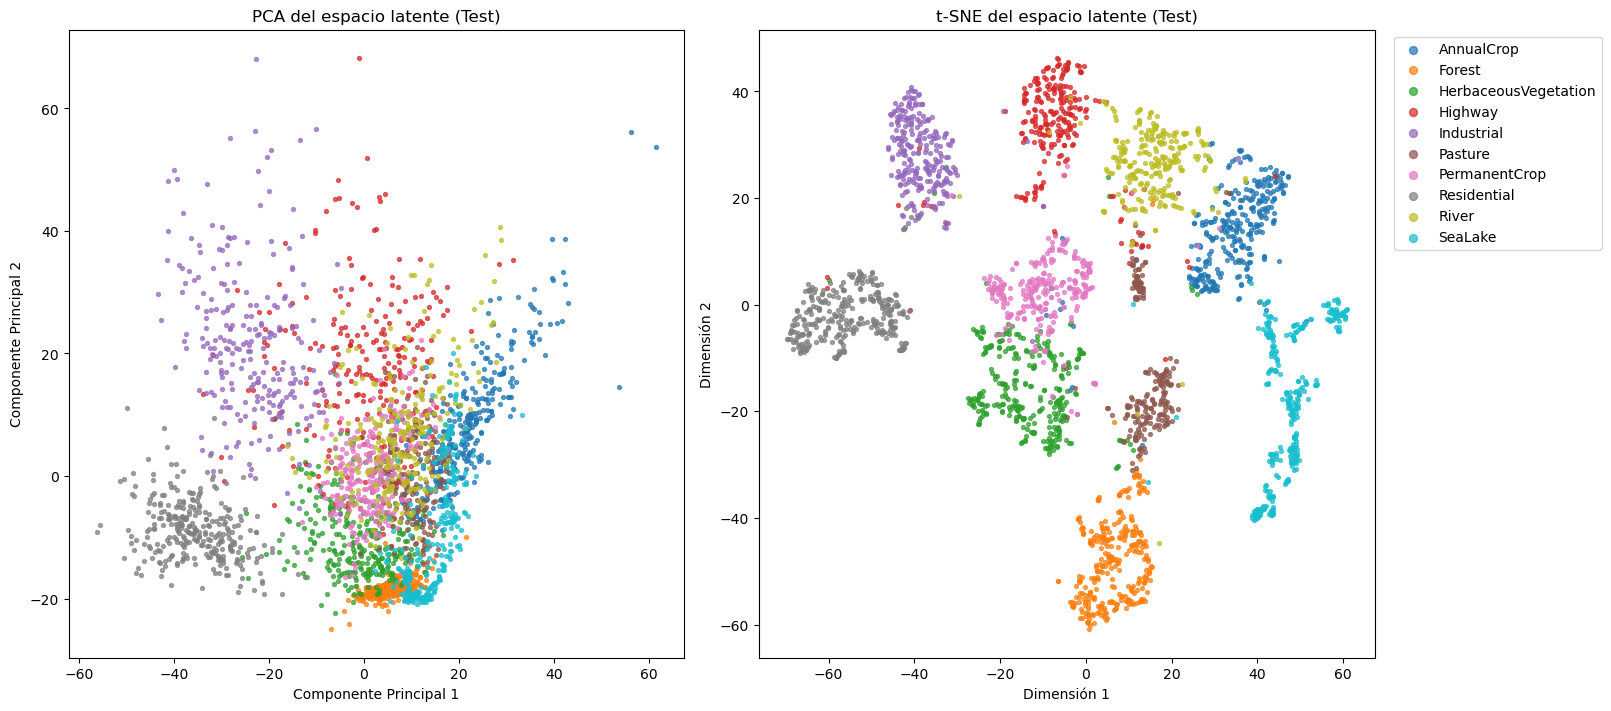

In [22]:
import os
# Evita el conflicto de hilos de OpenMP/PyTorch que crashea el kernel en scikit-learn
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

import gc
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# red_v2 sin su última capa lineal (vector latente de 128 características)
extractor = red_v2[:-1]
extractor.eval()

features_list = []
with torch.no_grad():
    for x, y in test_loader:
        salida = extractor(x)
        features_list.append(salida.cpu())

features = torch.cat(features_list, dim=0).numpy()
print(f"Forma de los features: {features.shape}")

# Limpiamos memoria intermedia
del features_list
gc.collect()

# PCA a 50 dimensiones
pca = PCA(n_components=50, random_state=0)
features_pca = pca.fit_transform(features)

print(f"Varianza explicada con 2 componentes: {pca.explained_variance_ratio_[:2].sum():.3f}")
print(f"Varianza explicada con 50 componentes: {pca.explained_variance_ratio_.sum():.3f}")

# t-SNE a 2 dimensiones (n_jobs=1 para evitar colisiones multihilo)
tsne = TSNE(n_components=2, perplexity=30, random_state=0, n_jobs=1)
coords_tsne = tsne.fit_transform(features_pca)

# Gráfico comparativo
fig, axs = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
y_test_np = y_test.numpy() if isinstance(y_test, torch.Tensor) else y_test

for i, clase in enumerate(clases):
    filtro = (y_test_np == i)
    axs[0].scatter(features_pca[filtro, 0], features_pca[filtro, 1], s=8, alpha=0.7, label=clase, color=plt.cm.tab10(i))
    axs[1].scatter(coords_tsne[filtro, 0], coords_tsne[filtro, 1], s=8, alpha=0.7, label=clase, color=plt.cm.tab10(i))

axs[0].set_title("PCA del espacio latente (Test)")
axs[0].set_xlabel("Componente Principal 1")
axs[0].set_ylabel("Componente Principal 2")

axs[1].set_title("t-SNE del espacio latente (Test)")
axs[1].set_xlabel("Dimensión 1")
axs[1].set_ylabel("Dimensión 2")
axs[1].legend(markerscale=2, bbox_to_anchor=(1.02, 1), loc="upper left")

plt.show()

> ### Análisis del Espacio Latente (PCA y t-SNE):
> 
> Analizamos la representación interna de 128 dimensiones extraída justo antes de la capa de clasificación lineal (`red_v2[:-1]`):
> 
> - **Compresión con PCA:** 
>   - Las primeras **2 componentes principales explican el 41.0%** de la varianza total de los features, mientras que **50 componentes retienen el 98.6%** de la información. Esto evidencia que el espacio latente de 128 dimensiones es altamente redundante y que prácticamente toda la estructura útil para discriminar clases reside en un subespacio de menor dimensión.
>   - En el plano PCA 2D se aprecia una separación global por grandes dominios (zonas urbanas construidas a la izquierda y coberturas naturales/vegetales hacia el centro e inferior), aunque con bastante solapamiento debido a la naturaleza estrictamente lineal de la proyección.
> 
> - **Estructura no lineal con t-SNE:**
>   - Al capturar relaciones de vecindad no lineales, **t-SNE revela clusters bien definidos y compactos** para la gran mayoría de las clases antes de la decisión final de la red.
>   - **Clusters altamente aislados:** Clases como **Residential** (gris, a la izquierda), **Industrial** (violeta, superior izquierda) y **Forest** (naranja, inferior) forman agrupaciones nítidas y distantes del resto. Esto coincide con sus altos F1-scores en test (0.987, 0.957 y 0.985, respectivamente). **SeaLake** (celeste, extrema derecha) también forma un continuo alargado bien separado.
> 
> - **Correspondencia directa con la Matriz de Confusión:**
>   - **Highway y River:** En el t-SNE, el cluster de **Highway** (rojo) y el de **River** (amarillo verdoso) se ubican contiguos en la parte superior, e incluso comparten puntos fronterizos intercalados. Esto justifica visualmente por qué representan la mayor confusión individual del modelo (12 falsos ríos en Highway y 4 en sentido inverso).
>   - **Familia de vegetación y cultivos:** Las clases **PermanentCrop** (rosa), **HerbaceousVegetation** (verde), **Pasture** (marrón) y **AnnualCrop** (azul) forman clusters adyacentes en el centro del mapa. Se observa que puntos periféricos de Pasture tocan a HerbaceousVegetation y a AnnualCrop, lo que explica por qué Pasture tuvo el menor recall (0.885) y dispersó errores hacia esas clases (6 errores hacia cada una).
> 
> **Conclusión sobre la representación interna:** Las clases ya se encuentran fuertemente separadas en el espacio latente de 128 dimensiones antes de la capa final. La última capa densa opera principalmente trazando hiperplanos de separación lineal sobre clusters que la parte convolucional ya organizó de forma coherente según la semántica visual del terreno.

#### 4- Transfer Learning.

> Basicamente, en esta parte en vez de entrenar una red desde cero, como hicimos con red_v2, usamos una red que ya viene entrenada con ImageNet, que es un dataset de más de un millón de fotos de 1000 clases distintas. La intuición es que esta red ya aprendió a ver cosas generales, como bordes, colores y texturas, y eso también sirve para nuestras imágenes satelitales, aunque nunca haya visto una. O sea, no arrancamos de cero, sino que aprovechamos lo que ya sabe y solo le enseñamos lo nuevo. Lo único que sí o sí tenemos que cambiar es la última capa, ya que ImageNet tiene 1000 clases y nosotros tenemos 10.

> Elegimos ResNet18 por dos motivos. Por un lado, es mucho más liviana que VGG16 (unos 11 millones de parámetros contra unos 138 millones), y como entrenamos en CPU, sin GPU, esto es clave para que no tarde horas. Por otro lado, tiene bloques residuales, o sea que la salida de cada bloque es H(x) = F(x) + x: el bloque solo aprende lo que le tiene que sumar a la entrada, y el gradiente puede pasar directo por el atajo (el "+ x"), por lo que la red puede ser profunda sin tener el problema de vanishing gradients.

> **Paso 1: normalizar como espera ResNet.** ResNet18 aprendió con imágenes normalizadas con la media y el desvío de ImageNet, no con los nuestros de EuroSAT. Si le pasamos las imágenes como las teníamos, le estaríamos dando los colores en una escala distinta a la que está acostumbrada, entonces lo que aprendió no le serviría tanto. Por eso, en esta celda primero deshacemos nuestra normalización (volvemos los valores a [0, 1]) y después aplicamos la de ImageNet. A la función a_imagenet le entra un tensor de imágenes normalizado como en la Parte 1 y nos devuelve el mismo tensor, pero normalizado como ImageNet. Con eso armamos los tres loaders nuevos (train, validation y test). Al final imprimimos la media y el desvío de un batch, que ya no dan exactamente 0 y 1, ya que ahora usamos la media y el desvío de ImageNet y no los de nuestras imágenes.

> Una aclaración: dejamos las imágenes en 64 × 64, igual que en la red propia, aunque ResNet18 se entrenó con imágenes de 224 × 224. Agrandarlas podría mejorar el resultado, pero cada época tardaría mucho más en CPU, así que es una limitación de nuestro experimento.

In [15]:
from torchvision import models
from sklearn.metrics import f1_score
import json

# Media y desvío por canal (R, G, B) de ImageNet, los que usó ResNet18 al entrenarse
media_imagenet = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
desvio_imagenet = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def a_imagenet(X):
    '''Deshace la normalización de EuroSAT y aplica la de ImageNet.'''
    X_original = X * desvio.view(1, 3, 1, 1) + media.view(1, 3, 1, 1)  # vuelve a [0, 1]
    return (X_original - media_imagenet) / desvio_imagenet

train_loader_tl = DataLoader(TensorDataset(a_imagenet(X_train), y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader_tl = DataLoader(TensorDataset(a_imagenet(X_val), y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader_tl = DataLoader(TensorDataset(a_imagenet(X_test), y_test), batch_size=BATCH_SIZE, shuffle=False)

# Control: con la normalización de ImageNet, nuestras imágenes ya no quedan exactamente en media 0 y desvío 1
x_batch_tl, _ = next(iter(val_loader_tl))
print(f"Media por canal de un batch de validation: {x_batch_tl.mean(dim=(0, 2, 3))}")
print(f"Desvío por canal de un batch de validation: {x_batch_tl.std(dim=(0, 2, 3))}")

Media por canal de un batch de validation: tensor([-0.5575, -0.3178,  0.0155])
Desvío por canal de un batch de validation: tensor([0.9107, 0.6195, 0.4986])


> Como vemos, después de aplicar la normalización de ImageNet las medias de nuestras imágenes quedan en -0.56, -0.32 y 0.02 (R, G, B), y los desvíos en 0.91, 0.62 y 0.50. O sea que, comparadas con las fotos de ImageNet, nuestras imágenes son más oscuras en el rojo y el verde, y tienen menos contraste en los tres canales. Esto no es un problema, ya que lo importante es que la red reciba los colores en la misma escala con la que aprendió.

> **Paso 2: adaptar la red.** En esta celda descargamos ResNet18 con los pesos de ImageNet y la adaptamos a nuestro problema. "Congelar" una capa significa que sus pesos no se actualizan cuando entrenamos, o sea que quedan como vinieron. Lo que hicimos fue congelar toda la red, después descongelar solo el último bloque (layer4) y por último reemplazar la capa final (fc) por una nueva de 512 a 10 salidas, una por clase (la capa nueva ya arranca descongelada).

> ¿Por qué solo el final? Las primeras capas detectan cosas generales, como bordes y texturas, que sirven igual para fotos satelitales, por eso las dejamos como están. En cambio, las últimas capas detectan cosas más específicas de las clases de ImageNet (por ejemplo caras de perro o ruedas de auto), que a nosotros no nos sirven, por eso las reentrenamos para nuestras clases. Si descongeláramos más capas, la red se podría adaptar más, pero tardaría más y tendría más riesgo de overfitting. Al final imprimimos cuántos parámetros tiene en total y cuántos vamos a entrenar.

In [16]:
torch.manual_seed(0)  # inicialización reproducible de la capa final nueva
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)  # la primera vez descarga 45 MB

# Congelamos toda la red
for parametro in resnet.parameters():
    parametro.requires_grad = False

# Descongelamos el último bloque
for parametro in resnet.layer4.parameters():
    parametro.requires_grad = True

# Reemplazamos la capa final: 10 clases en lugar de 1000 (una capa nueva arranca descongelada)
resnet.fc = nn.Linear(512, 10)

total_resnet = sum(p.numel() for p in resnet.parameters())
entrenables_resnet = sum(p.numel() for p in resnet.parameters() if p.requires_grad)
print(f"Parámetros totales: {total_resnet:,}; entrenables: {entrenables_resnet:,} ({entrenables_resnet / total_resnet:.0%})")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/lisandrorusso/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


Parámetros totales: 11,181,642; entrenables: 8,398,858 (75%)


> Vemos que la red tiene 11.181.642 parámetros en total, y vamos a entrenar 8.398.858 (el 75%). Puede parecer raro que, congelando casi todo, entrenemos el 75%, pero es porque el último bloque es el más pesado: tiene muchos filtros (512) y por eso concentra la mayoría de los parámetros. Igual es más de 7 veces lo que entrena la red propia (1.143.242).

> **Paso 3: entrenar.** Acá definimos la función de entrenamiento, entrenar_tl. Es basicamente la misma que entrenar_v2 de la Parte 1: en cada época recorre los batches de train, les aplica data augmentation, calcula la loss, hace backpropagation y actualiza los pesos. Al final de cada época mide la loss y el accuracy en validation y se guarda los pesos de la mejor época (early stopping). No pudimos reutilizar entrenar_v2 por dos motivos: primero, recorre la red capa por capa para guardar los gradientes, lo cual funciona con nn.Sequential pero no con ResNet; segundo, usa los loaders con la normalización de EuroSAT y nosotros necesitamos los de ImageNet. Por eso esta versión no guarda gradientes y recibe los loaders como parámetros. Otro detalle es que al optimizador solo le pasamos los parámetros descongelados, ya que los congelados no los queremos tocar.

> Sobre las decisiones que tomamos: usamos un learning rate de 0.0001, diez veces más chico que el de la red propia, ya que los pesos ya son buenos y queremos ajustarlos de a poco, sin romper lo que aprendió con ImageNet. Usamos el mismo data augmentation que antes (espejos y rotaciones de 90°). Por último, las capas de BatchNorm de ResNet actualizan sus promedios internos cuando la red está en modo train(), aunque estén congeladas. Esto no cambia los pesos, pero es algo a tener en cuenta.

In [17]:
def entrenar_tl(red, n_epocas, train_loader, val_loader, lr=0.0001):
    '''Igual que entrenar_v2, sin registrar gradientes y recibiendo los loaders.'''
    # Solo le pasamos al optimizador los parámetros descongelados
    optimizer = torch.optim.Adam([p for p in red.parameters() if p.requires_grad], lr=lr)
    criterion = nn.CrossEntropyLoss()
    historia = {"loss_train": [], "acc_train": [], "loss_val": [], "acc_val": [], "tiempo": []}
    mejor_acc, mejor_epoca, mejor_estado = 0, 0, None

    for epoca in range(n_epocas):
        inicio = time.time()
        red.train()
        loss_total, aciertos, n = 0, 0, 0

        for x, y in train_loader:
            x = aumentar(x)
            optimizer.zero_grad()
            salida = red(x)
            loss = criterion(salida, y)
            loss.backward()
            optimizer.step()

            loss_total += loss.item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            n += len(y)

        historia["loss_train"].append(loss_total / n)
        historia["acc_train"].append(aciertos / n)
        loss_val, acc_val = evaluar(red, val_loader, criterion)
        historia["loss_val"].append(loss_val)
        historia["acc_val"].append(acc_val)
        historia["tiempo"].append(time.time() - inicio)

        if acc_val > mejor_acc:
            mejor_acc, mejor_epoca = acc_val, epoca + 1
            mejor_estado = copy.deepcopy(red.state_dict())

        print(f"Época {epoca + 1:2d}/{n_epocas} | "
              f"loss train {historia['loss_train'][-1]:.3f}, val {loss_val:.3f} | "
              f"acc train {historia['acc_train'][-1]:.3f}, val {acc_val:.3f} | "
              f"{historia['tiempo'][-1]:.0f} s")

    red.load_state_dict(mejor_estado)
    print(f"\nMejor época: {mejor_epoca} (accuracy validation = {mejor_acc:.3f})")
    historia["mejor_epoca"] = mejor_epoca
    return historia

> Entrenamos 15 épocas como punto de partida. Si alcanzan o no lo decidimos mirando las curvas de validation, nunca test. Esta celda es la que más tarda, alrededor de 45 minutos en CPU (en una prueba de una época tardó 190 s). Cuando termina, guardamos los pesos de la mejor época en resnet18_tl.pt y la historia del entrenamiento (métricas y tiempos de cada época) en historia_tl.json, para no tener que reentrenar.

In [18]:
N_EPOCAS_TL = 15

torch.manual_seed(0)  # orden de los batches y augmentation reproducibles
historia_tl = entrenar_tl(resnet, N_EPOCAS_TL, train_loader_tl, val_loader_tl)

# Guardamos los pesos de la mejor época y la historia (métricas y tiempos por época)
torch.save(resnet.state_dict(), "resnet18_tl.pt")
with open("historia_tl.json", "w") as archivo:
    json.dump(historia_tl, archivo)

Época  1/15 | loss train 0.422, val 0.205 | acc train 0.867, val 0.931 | 127 s
Época  2/15 | loss train 0.190, val 0.166 | acc train 0.938, val 0.943 | 128 s
Época  3/15 | loss train 0.152, val 0.138 | acc train 0.949, val 0.953 | 127 s
Época  4/15 | loss train 0.130, val 0.146 | acc train 0.955, val 0.950 | 136 s
Época  5/15 | loss train 0.118, val 0.132 | acc train 0.959, val 0.958 | 133 s
Época  6/15 | loss train 0.099, val 0.129 | acc train 0.966, val 0.958 | 134 s
Época  7/15 | loss train 0.093, val 0.133 | acc train 0.969, val 0.954 | 135 s
Época  8/15 | loss train 0.083, val 0.128 | acc train 0.972, val 0.959 | 140 s
Época  9/15 | loss train 0.073, val 0.132 | acc train 0.975, val 0.956 | 141 s
Época 10/15 | loss train 0.067, val 0.130 | acc train 0.977, val 0.957 | 143 s
Época 11/15 | loss train 0.067, val 0.125 | acc train 0.977, val 0.959 | 144 s
Época 12/15 | loss train 0.060, val 0.133 | acc train 0.980, val 0.957 | 147 s
Época 13/15 | loss train 0.054, val 0.121 | acc trai

> Esta celda carga los pesos y la historia que guardamos, o sea que si se reinicia el notebook no hace falta volver a entrenar: alcanza con correr la celda del Paso 2 (crear la red) y esta. Si la corremos justo después de entrenar no cambia nada, ya que carga los mismos pesos. También medimos el accuracy en validation, para confirmar que se cargó bien. Después graficamos la loss y el accuracy de train y validation por época, igual que en la Parte 1, marcando la mejor época.

In [19]:
resnet.load_state_dict(torch.load("resnet18_tl.pt"))
with open("historia_tl.json") as archivo:
    historia_tl = json.load(archivo)

loss_val_tl, acc_val_tl = evaluar(resnet, val_loader_tl, nn.CrossEntropyLoss())
print(f"Validation: loss {loss_val_tl:.3f}, accuracy {acc_val_tl:.3f} (mejor época: {historia_tl['mejor_epoca']})")

Validation: loss 0.120, accuracy 0.963 (mejor época: 14)


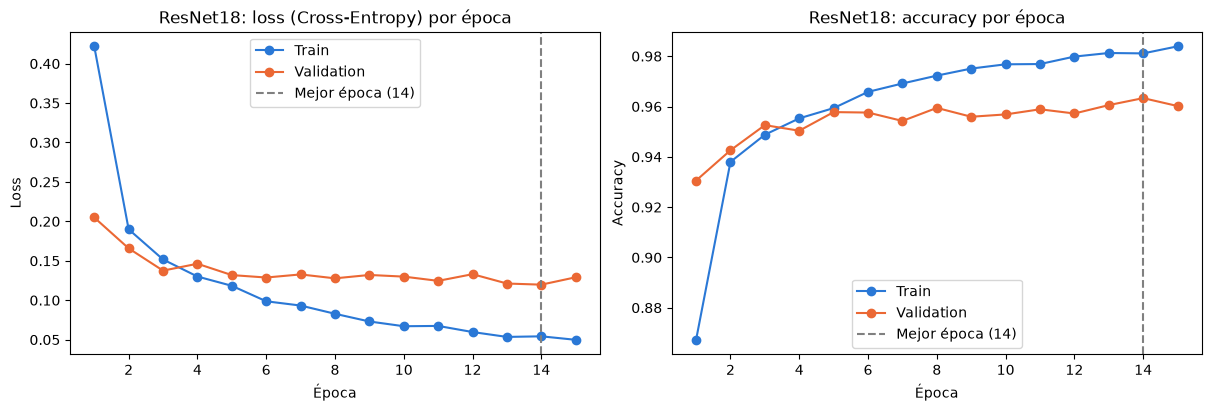

In [20]:
epocas_tl = range(1, len(historia_tl["acc_val"]) + 1)
mejor_tl = historia_tl["mejor_epoca"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

ax1.plot(epocas_tl, historia_tl["loss_train"], "o-", label="Train", color="#2a78d6")
ax1.plot(epocas_tl, historia_tl["loss_val"], "o-", label="Validation", color="#eb6834")
ax1.axvline(mejor_tl, color="gray", linestyle="--", label=f"Mejor época ({mejor_tl})")
ax1.set_title("ResNet18: loss (Cross-Entropy) por época")
ax1.set_xlabel("Época")
ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(epocas_tl, historia_tl["acc_train"], "o-", label="Train", color="#2a78d6")
ax2.plot(epocas_tl, historia_tl["acc_val"], "o-", label="Validation", color="#eb6834")
ax2.axvline(mejor_tl, color="gray", linestyle="--", label=f"Mejor época ({mejor_tl})")
ax2.set_title("ResNet18: accuracy por época")
ax2.set_xlabel("Época")
ax2.set_ylabel("Accuracy")
ax2.legend()
plt.show()

> Viendo las curvas, lo primero que llama la atención es lo rápido que aprende ResNet18: en la primera época ya llega a 0.931 de accuracy en validation, y en la época 3 ya pasa 0.95 (0.953). Esto es justamente lo que esperábamos del transfer learning, ya que la red no arranca de cero, sino que ya sabe detectar bordes y texturas y solo tiene que aprender a usarlos para nuestras clases. Después de la época 5 el accuracy de validation se estanca, o sea que oscila entre 0.954 y 0.963 sin una tendencia clara, y la loss de validation queda entre 0.120 y 0.133. La mejor época fue la 14 (accuracy 0.963, loss 0.120) y nos quedamos con esos pesos.

> Con respecto al overfitting, podemos ver que la loss de train sigue bajando hasta el final (de 0.422 en la época 1 a 0.050 en la 15), mientras que la de validation ya no baja, por lo que la brecha entre las dos va creciendo (en la época 15, accuracy 0.984 en train contra 0.960 en validation). Como validation no empeora, no hay un overfitting claro, pero sí es una señal de que entrenar muchas más épocas no tendría sentido, ya que la red empezaría a memorizar train sin mejorar en validation. Por eso las 15 épocas alcanzan. Igual, como elegimos la época 14 mirando validation, su 0.963 es un poco optimista; la estimación honesta es la de test.

> **Paso 4: evaluar en test.** Igual que con la red propia, usamos test una sola vez, con los pesos de la mejor época según validation, ya que si eligiéramos algo mirando test, el resultado dejaría de ser una estimación honesta. Primero sacamos el reporte de clasificación (precision, recall y F1 por clase). Después armamos la matriz de confusión de ResNet18 y una tabla que compara, para cada par de clases (real, predicha), cuántos errores tuvo cada red. Así podemos ver qué confusiones mejoraron y cuáles siguen.

In [21]:
pred_resnet = predecir(resnet, test_loader_tl)
print("Reporte de clasificación en test (ResNet18)")
print(classification_report(y_test, pred_resnet, target_names=clases, digits=3))

Reporte de clasificación en test (ResNet18)
                      precision    recall  f1-score   support

          AnnualCrop      0.976     0.957     0.966       300
              Forest      0.984     0.997     0.990       300
HerbaceousVegetation      0.957     0.967     0.962       300
             Highway      0.912     0.956     0.934       250
          Industrial      0.980     0.964     0.972       250
             Pasture      0.950     0.955     0.953       200
       PermanentCrop      0.932     0.932     0.932       250
         Residential      0.990     0.993     0.992       300
               River      0.959     0.924     0.941       250
             SeaLake      0.997     0.990     0.993       300

            accuracy                          0.965      2700
           macro avg      0.964     0.963     0.963      2700
        weighted avg      0.965     0.965     0.965      2700



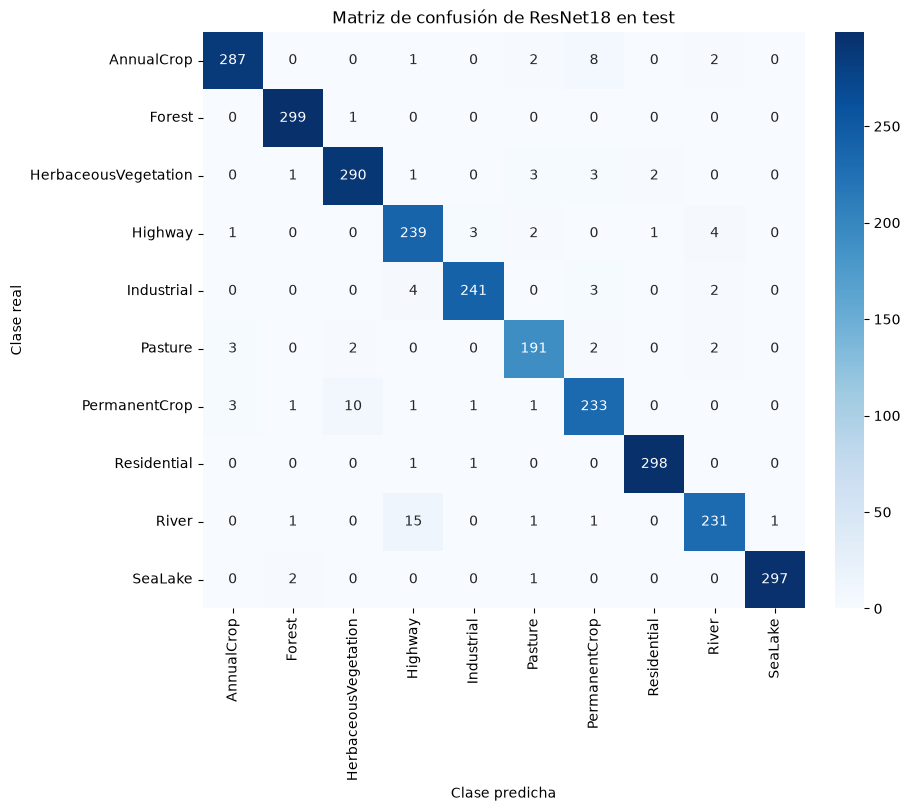

Errores totales en test: red_v2 122, ResNet18 94 (de 2700)

Confusiones más frecuentes en alguna de las dos redes:
                Real             Predicha  Errores red_v2  Errores ResNet18  Diferencia
               River              Highway               4                15          11
       PermanentCrop HerbaceousVegetation              15                10          -5
             Highway                River              13                 4          -9
          AnnualCrop        PermanentCrop               4                 8           4
          Industrial          Residential               6                 0          -6
             Pasture                River               6                 2          -4
             Pasture HerbaceousVegetation               6                 2          -4
HerbaceousVegetation        PermanentCrop               5                 3          -2
             Pasture           AnnualCrop               5                 3          -2
     

In [22]:
matriz_resnet = confusion_matrix(y_test, pred_resnet)

fig, ax = plt.subplots(figsize=(9, 8), constrained_layout=True)
sns.heatmap(matriz_resnet, annot=True, fmt="d", cmap="Blues", xticklabels=clases, yticklabels=clases, ax=ax)
ax.set_title("Matriz de confusión de ResNet18 en test")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
plt.show()

# Comparamos, para cada par (real, predicha), los errores de las dos redes
comparacion = []
for i, real in enumerate(clases):
    for j, predicha in enumerate(clases):
        if i != j and (matriz[i, j] > 0 or matriz_resnet[i, j] > 0):
            comparacion.append({"Real": real, "Predicha": predicha,
                                "Errores red_v2": matriz[i, j],
                                "Errores ResNet18": matriz_resnet[i, j],
                                "Diferencia": matriz_resnet[i, j] - matriz[i, j]})
comparacion = pd.DataFrame(comparacion)
comparacion["Máximo"] = comparacion[["Errores red_v2", "Errores ResNet18"]].max(axis=1)

print(f"Errores totales en test: red_v2 {matriz.sum() - matriz.trace()}, ResNet18 {matriz_resnet.sum() - matriz_resnet.trace()} (de {matriz.sum()})")
print("\nConfusiones más frecuentes en alguna de las dos redes:")
print(comparacion.sort_values("Máximo", ascending=False).drop(columns="Máximo").head(12).to_string(index=False))

> En test, ResNet18 llega a un accuracy de 0.965 y un F1 macro de 0.963, contra 0.955 y 0.953 de la red propia. O sea que se equivoca en 94 de las 2.700 imágenes, contra 122 de red_v2: 28 errores menos (un 23% menos). El accuracy de test (0.965) es muy parecido al de validation (0.963), por lo que elegir la mejor época mirando validation no nos dio un número inflado.

> Por clase, la que más mejoró fue Pasture, que era la más difícil para la red propia: el recall pasó de 0.890 a 0.955 y el F1 de 0.927 a 0.953. Basicamente, la red propia confundía 17 imágenes de Pasture (6 con River, 6 con HerbaceousVegetation y 5 con AnnualCrop) y ResNet18 solo 7 (2, 2 y 3). También mejoraron HerbaceousVegetation (F1 de 0.935 a 0.962), AnnualCrop (de 0.948 a 0.966) e Industrial (de 0.957 a 0.972), que dejó de confundirse con Residential (de 6 errores a 0).

> Pero no todo mejoró. La confusión entre Highway y River sigue siendo la principal, solo que cambió de dirección: la red propia confundía 13 autopistas con ríos y 4 ríos con autopistas, y ResNet18 confunde 4 autopistas con ríos y 15 ríos con autopistas (el 6% de los ríos). En total el par suma casi lo mismo (17 errores en la red propia y 19 en ResNet18). Por eso River bajó su recall (de 0.964 a 0.924) y Highway su precision (de 0.958 a 0.912). Esto nos dice que ResNet18 tampoco logra separar bien estas dos clases, que como vimos en el EDA son las dos una línea que cruza la imagen. Una posible explicación de por qué se dio vuelta la dirección es que cada red trazó la frontera entre las dos clases en un lugar distinto, pero no lo comprobamos. Algo parecido pasa con los cultivos: PermanentCrop confundida con HerbaceousVegetation bajó de 15 a 10 errores, pero sigue siendo la segunda confusión (4% de PermanentCrop), y AnnualCrop confundida con PermanentCrop subió de 4 a 8 (2.7% de AnnualCrop). Highway y PermanentCrop son las únicas dos clases en las que el F1 bajó, aunque poco (de 0.939 a 0.934 y de 0.937 a 0.932).

> **Paso 5: comparar con la red propia.** La consigna pide comparar las dos redes en tres cosas: velocidad de convergencia, rendimiento final y tiempo por época. Empezamos por la velocidad de convergencia, o sea, cuántas épocas necesita cada red para llegar a cierto accuracy de validation. La historia de red_v2 no quedó guardada en un archivo, así que copiamos su accuracy de validation por época de la salida del entrenamiento de la Parte 1. Con eso graficamos las dos curvas juntas y armamos una tabla con la primera época en la que cada red llega a 0.90, 0.93 y 0.95. La función primera_epoca hace basicamente eso: le entra la lista de accuracies y un umbral, y nos devuelve la primera época en la que se llega a ese umbral (o None si nunca llega).

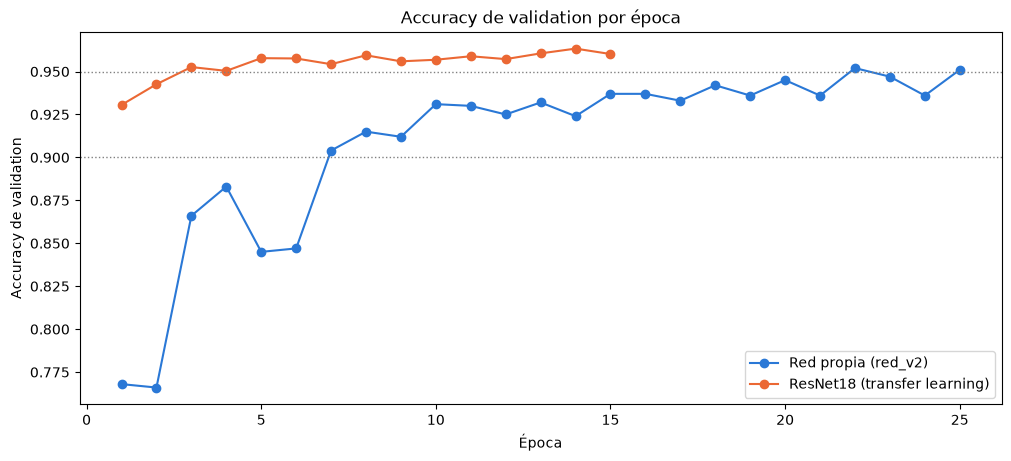

                                  Red propia  ResNet18
Primera época con acc val ≥ 0.90           7         1
≥ 0.93                                    10         1
≥ 0.95                                    22         3

Accuracy de validation después de 1 época: red propia 0.768, ResNet18 0.931


In [23]:
# Accuracy de validation de red_v2 por época, copiado del log de la Parte 1
acc_val_v2 = [0.768, 0.766, 0.866, 0.883, 0.845, 0.847, 0.904, 0.915, 0.912, 0.931,
              0.930, 0.925, 0.932, 0.924, 0.937, 0.937, 0.933, 0.942, 0.936, 0.945,
              0.936, 0.952, 0.947, 0.936, 0.951]

def primera_epoca(accs, umbral):
    '''Primera época (contando desde 1) en que el accuracy llega al umbral, o None si nunca llega.'''
    for epoca, acc in enumerate(accs, start=1):
        if acc >= umbral:
            return epoca
    return None

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
ax.plot(range(1, len(acc_val_v2) + 1), acc_val_v2, "o-", label="Red propia (red_v2)", color="#2a78d6")
ax.plot(range(1, len(historia_tl["acc_val"]) + 1), historia_tl["acc_val"], "o-", label="ResNet18 (transfer learning)", color="#eb6834")
for umbral in [0.90, 0.95]:
    ax.axhline(umbral, color="gray", linestyle=":", linewidth=1)
ax.set_title("Accuracy de validation por época")
ax.set_xlabel("Época")
ax.set_ylabel("Accuracy de validation")
ax.legend()
plt.show()

convergencia = pd.DataFrame({
    "Red propia": [primera_epoca(acc_val_v2, u) for u in [0.90, 0.93, 0.95]],
    "ResNet18": [primera_epoca(historia_tl["acc_val"], u) for u in [0.90, 0.93, 0.95]],
}, index=["Primera época con acc val ≥ 0.90", "≥ 0.93", "≥ 0.95"])
print(convergencia)
print(f"\nAccuracy de validation después de 1 época: red propia {acc_val_v2[0]:.3f}, ResNet18 {historia_tl['acc_val'][0]:.3f}")

> **Tiempo por época.** Para que la comparación sea justa, tenemos que medir las dos redes en la misma computadora y con la misma función, ya que los 104.6 s por época de la Parte 1 se midieron en otra laptop, y comparar tiempos de dos compus distintas no tiene sentido. Por eso entrenamos 5 épocas una copia de red_v2 (con copy.deepcopy, para que la red original no cambie), usando entrenar_tl. Acá solo nos importa el tiempo, no las métricas. Esta celda tarda unos 10 minutos.

> La función resumir_tiempos calcula la media y el desvío del tiempo por época. Si alguna época tarda más del doble que la mediana (por ejemplo porque la compu se suspendió, como nos pasó en la Parte 1), la informamos y la sacamos del promedio, en vez de borrarla sin avisar.

In [24]:
torch.manual_seed(0)
historia_tiempo_v2 = entrenar_tl(copy.deepcopy(red_v2), 5, train_loader, val_loader, lr=0.001)

def resumir_tiempos(tiempos, nombre):
    '''Media y desvío del tiempo por época, excluyendo épocas que tardan más del doble de la mediana.'''
    tiempos = torch.tensor(tiempos)
    normales = tiempos[tiempos <= 2 * tiempos.median()]
    anomalas = tiempos[tiempos > 2 * tiempos.median()]
    if len(anomalas) > 0:
        print(f"{nombre}: excluimos {len(anomalas)} época(s) anómala(s): {[round(t) for t in anomalas.tolist()]} s")
    print(f"{nombre}: {normales.mean():.1f} ± {normales.std():.1f} s por época ({len(normales)} épocas)")
    return normales.mean().item(), normales.std().item()

tiempo_v2, desvio_tiempo_v2 = resumir_tiempos(historia_tiempo_v2["tiempo"], "Red propia")
tiempo_tl, desvio_tiempo_tl = resumir_tiempos(historia_tl["tiempo"], "ResNet18")
print(f"\nResNet18 tarda {tiempo_tl / tiempo_v2:.1f} veces más por época que la red propia")

Época  1/5 | loss train 0.104, val 0.180 | acc train 0.964, val 0.939 | 37 s
Época  2/5 | loss train 0.109, val 0.205 | acc train 0.961, val 0.934 | 36 s
Época  3/5 | loss train 0.099, val 0.150 | acc train 0.966, val 0.952 | 36 s
Época  4/5 | loss train 0.096, val 0.171 | acc train 0.966, val 0.946 | 36 s
Época  5/5 | loss train 0.087, val 0.181 | acc train 0.970, val 0.947 | 36 s

Mejor época: 3 (accuracy validation = 0.952)
Red propia: 36.0 ± 0.4 s por época (5 épocas)
ResNet18: 137.5 ± 6.8 s por época (15 épocas)

ResNet18 tarda 3.8 veces más por época que la red propia


> **Tabla resumen.** Por último, juntamos las tres comparaciones en una sola tabla. Agregamos también el tiempo estimado hasta llegar a 0.90 y a 0.95 de accuracy, que junta las dos cosas: cuántas épocas necesita cada red y cuánto tarda cada época en esta computadora (épocas × segundos por época). Esto es importante, ya que una red puede tardar más por época pero necesitar menos épocas, y lo que realmente importa es el tiempo total.

In [26]:
def fmt_epoca(e):
    return "no llega" if e is None else str(e)

def fmt_minutos(e, segundos_por_epoca):
    return "no llega" if e is None else f"{e * segundos_por_epoca / 60:.1f} min"

total_v2 = sum(p.numel() for p in red_v2.parameters())
e90_v2, e95_v2 = primera_epoca(acc_val_v2, 0.90), primera_epoca(acc_val_v2, 0.95)
e90_tl, e95_tl = primera_epoca(historia_tl["acc_val"], 0.90), primera_epoca(historia_tl["acc_val"], 0.95)

resumen_tl = pd.DataFrame({
    "Red propia": [
        f"{total_v2:,} / {total_v2:,}",
        fmt_epoca(e90_v2), fmt_epoca(e95_v2),
        f"{max(acc_val_v2):.3f} ({acc_val_v2.index(max(acc_val_v2)) + 1})",
        f"{(pred_custom == y_test).float().mean():.3f}",
        f"{f1_score(y_test, pred_custom, average='macro'):.3f}",
        f"{tiempo_v2:.1f} ± {desvio_tiempo_v2:.1f} s",
        fmt_minutos(e90_v2, tiempo_v2), fmt_minutos(e95_v2, tiempo_v2),
    ],
    "ResNet18": [
        f"{total_resnet:,} / {entrenables_resnet:,}",
        fmt_epoca(e90_tl), fmt_epoca(e95_tl),
        f"{max(historia_tl['acc_val']):.3f} ({historia_tl['mejor_epoca']})",
        f"{(pred_resnet == y_test).float().mean():.3f}",
        f"{f1_score(y_test, pred_resnet, average='macro'):.3f}",
        f"{tiempo_tl:.1f} ± {desvio_tiempo_tl:.1f} s",
        fmt_minutos(e90_tl, tiempo_tl), fmt_minutos(e95_tl, tiempo_tl),
    ],
}, index=[
    "Parámetros totales / entrenables",
    "Primera época con acc val ≥ 0.90",
    "Primera época con acc val ≥ 0.95",
    "Mejor acc val (época)",
    "Accuracy en test",
    "F1 macro en test",
    "Tiempo por época (esta compu)",
    "Tiempo estimado hasta acc val ≥ 0.90",
    "Tiempo estimado hasta acc val ≥ 0.95",
])
resumen_tl

,Red propia,ResNet18
Parámetros totales / entrenables,"1,143,242 / 1,143,242","11,181,642 / 8,398,858"
Primera época con acc val ≥ 0.90,7,1
Primera época con acc val ≥ 0.95,22,3
Mejor acc val (época),0.952 (22),0.963 (14)
Accuracy en test,0.955,0.965
F1 macro en test,0.953,0.963
Tiempo por época (esta compu),36.0 ± 0.4 s,137.5 ± 6.8 s
Tiempo estimado hasta acc val ≥ 0.90,4.2 min,2.3 min
Tiempo estimado hasta acc val ≥ 0.95,13.2 min,6.9 min


> **Conclusión.** Comparando las dos redes en los tres puntos que pide la consigna:

> **Velocidad de convergencia:** ResNet18 converge mucho más rápido en épocas. Después de una sola época ya tiene 0.931 de accuracy en validation, mientras que la red propia tiene 0.768. Para llegar a 0.90 la red propia necesita 7 épocas y ResNet18 una sola, y para llegar a 0.95 necesita 22 épocas contra 3. Esto se debe a que ResNet18 ya viene con lo que aprendió en ImageNet, y solo tiene que adaptarlo.

> **Rendimiento final:** ResNet18 es mejor, pero no por mucho. Gana por un punto en accuracy de test (0.965 contra 0.955) y en F1 macro (0.963 contra 0.953), con 28 errores menos, y mejora sobre todo a Pasture. Pero la confusión principal, Highway con River, sigue estando.

> **Tiempo por época:** acá gana la red propia. Medidas en la misma computadora, una época de ResNet18 tarda 137.5 ± 6.8 s y una de la red propia 36.0 ± 0.4 s, o sea 3.8 veces más. Tiene sentido, ya que ResNet18 tiene casi 10 veces más parámetros (11.2 millones contra 1.1 millones) y entrena más de 7 veces más (8.4 millones contra 1.1 millones). Además, el tiempo por época de ResNet18 fue subiendo, de 127 s en la primera época a 148 s en la 14; una posible causa es que la compu se fue calentando, pero no lo comprobamos.

> Juntando todo, lo que realmente importa es el tiempo total. Aunque cada época de ResNet18 tarda casi 4 veces más, necesita muchas menos épocas, por lo que llega a 0.95 en unos 6.9 minutos (3 épocas) contra unos 13.2 minutos de la red propia (22 épocas). Estos tiempos son estimaciones (épocas × tiempo medio por época en esta compu). O sea que con transfer learning llegamos a un mejor resultado y en menos tiempo. Lo que se paga es una red mucho más pesada (el archivo de pesos ocupa 45 MB, contra 4.6 MB de la red propia) y que depende de haber sido preentrenada con otro dataset. La red propia, en cambio, es más liviana y cada época es más rápida, pero necesita muchas más épocas y termina un poco peor. Por último, como usamos imágenes de 64 × 64 y ResNet18 se entrenó con imágenes de 224 × 224, puede ser que agrandando las imágenes ResNet18 mejore todavía más, aunque tardaría mucho más por época.